# Why random nudges stopped changing the algorithm
### Plan-noise dose unit × direction seeds on Qwen3-8B (iteration 7, step K): demo notebook

**The research question.** How does "creativity", meaning a *different* algorithm for the same coding task, show up
inside an LLM, and can we push it? Qwen3-8B (bf16, thinking off) nearly always writes one default algorithm per task.
For **T10 (count the connected components of a graph)** the default is **union-find**. The other catalogue algorithms
are DFS, BFS and label propagation.

**Plan noise (PN).** For every sample, a fresh isotropic random direction `u` is pushed into the task-specification
positions of decoder blocks 12–23, during the prompt prefill only. The edit is displacement-targeted:
`h ← h + (α·n[l,p] − (h − h_twin)·u) u`, so the displacement from the clean twin along `u` is exactly `α·n[l,p]`.

**The puzzle.** Iteration 4's plan noise moved T10 off union-find on 25 of 50 programs; iteration 5's on 1 of 50. The
two designs differ in:
1. **the dose unit.** `U_abs` is the per-block, per-position displacement norm `n[l,p]` that a real prompt *ban*
   writes into the residual stream. `U_bf = ‖h_twin[l,p]‖ · r_Q(l)` is a ban-free unit.
2. **the direction seeds.** `S4` and `S5` are two PCG64 seedings of `u`.
3. **the decoding path.** Left-padded or shared-prefix decoding.

This experiment crosses unit × seeds on shared **common-random-number (CRN) slots**. A slot is a (prompt template,
sample index k) pair. Every arm of a slot shares the clean twin's prompt ids and one uniform stream for the sampler,
so the arms of a slot differ only in the push.

| design | dose unit | seeds |
|---|---|---|
| D1 | U_abs | S4 (iteration 4's design) |
| D2 | U_abs | S5 |
| D3 | U_bf | S4 |
| D4 | U_bf | S5 (iteration 5's design) |
| D5 | U_bf* = U_bf's within-block profile at U_abs's per-block energy | S4 |
| P_top / P_rest / P_shuf (S2) | U_abs on its top-quartile cells only / on the other cells / with the spec positions permuted | S4 |

**What this notebook runs.** The GPU stages cannot run in a 10-minute Colab session: they generated 2,880 programs in
about 0.66 GPU-h on an RTX 4090 with a 16 GB bf16 model. The judge calls go through OpenRouter. So the notebook does
three things:
1. It shows the pipeline entry point `method.py` as written, with its step table.
2. It re-runs the **CPU analysis stage** on the **1,250 labelled T10 programs** those GPU stages produced. They cover
   100 CRN slots: the 50 committed S1/S2 slots (k 0–9) and 50 fresh E3 slots (k 10–19). The code is the original
   `src/analysis_k.py`, `src/k_units.py`, `src/extensions_k.py` and `src/figures_k.py`; only the file reads point at
   the loaded demo data.
3. It compares every recomputed T10 headline number with the number the artifact reported (section 10).

With the default configuration (all 100 slots, and the artifact's own 2,000 bootstraps and 100,000 sign flips), all
36 quantities compared in section 10 match the reported values exactly. The analysis runs in well under a minute on a
CPU.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, pandas, scipy, statsmodels, scikit-learn, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'scikit-learn==1.6.1',
         'matplotlib==3.10.0')

**Imports.** The first block is `method.py`'s own import block, unchanged. The second block holds what the analysis
modules import (`src/k_cfg.py`, `src/analysis_k.py`, `src/figures_k.py`). scipy, statsmodels and scikit-learn are
imported inside the functions that use them, as in the original. The notebook-only additions:
- `base64` decodes the fp16 displacement vectors stored in the demo data;
- a warnings filter silences statsmodels' expected "Dropped N groups" message.

In [2]:
from __future__ import annotations

# --- method.py
import os
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/k_cfg.py, src/analysis_k.py, src/figures_k.py
import hashlib
import itertools
import json
import math
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Iterable

import matplotlib.pyplot as plt
import numpy as np

# --- notebook only
import base64
import warnings

# statsmodels' ConditionalLogit warns on every fit that it dropped the slots without within-slot variation (expected,
# see section 5); silenced to keep the outputs readable
warnings.filterwarnings("ignore", message=r"Dropped \d+ groups and \d+ observations", category=UserWarning)

**Data.** `mini_demo_data.json` is the demo subset: one task (T10) with 100 CRN slots. Each example is one slot and
holds:
- `raw` and `labels`: for every arm generated on the slot (twin, D1–D4 at α 1 and 2, D5, P_top, P_rest, P_shuf, and
  the E1 doses of D3), the fields that `analysis_k.load_joined()` reads from `data/raw/raw_k.jsonl` and
  `data/labels.jsonl`;
- `realised`: the 36-block realised-displacement profiles of the α-2 pushes, from `data/realised_disp.jsonl`;
- `disp_R35`: on the committed slots, the fp16 block-35 displacement vectors (4,096-d) from `cache/disp/`.

`metadata` holds the T10 catalogue and the dose-unit matrices from `cache/units/T10.npz`. It also holds exp29's
labels for the anchor and the numbers the artifact reported.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-7/experiment-36/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["artifact"])
print(f"model {meta['model']} @ {meta['model_revision'][:8]}; task {meta['task']}: {meta['task_name']}")
print(f"default algorithm: {meta['default_algorithm']}; catalogue: {meta['catalogue'][meta['task']]}")
print(f"{len(data['examples'])} CRN slots, {sum(len(e['raw']) for e in data['examples'])} labelled programs")

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
experiment-36 (iteration 7, step K): why random nudges stopped changing the algorithm
model Qwen/Qwen3-8B @ b968826d; task T10: connected components of an undirected graph: solve(n, edges)
default algorithm: union_find; catalogue: ['bfs', 'dfs', 'union_find', 'label_propagation']
100 CRN slots, 1250 labelled programs


## Configuration

These are all the tunable parameters. The defaults are the artifact's own values, and the full analysis finishes in
well under the 10-minute budget. Smaller values run faster, but the CIs and Monte-Carlo p-values then no longer match
the reported ones.

- `MAX_EXAMPLES`: how many CRN slots of the demo data are analysed. The slots are ordered k-major (k 0 for W1–W5,
  then k 1, and so on), so 50 = the committed S1/S2 slots and 100 adds the fresh E3 slots. The anchors need all 50
  committed slots, and E3 needs 100.
- `N_BOOT`: slot-cluster bootstrap replicates behind every 95% CI.
- `N_FLIP`: Monte-Carlo sign flips, used when more than 20 slots contribute to a contrast. With at most 20 the test
  enumerates every sign pattern exactly.
- `BOOT_SEED`: keep it to reproduce the reported intervals.
- `FIG_TASKS`: the tasks drawn by the figure functions (the originals draw T10 and T2).

The function defaults bind these values when their cells run, so after a change re-run the notebook from this cell
downward.

In [5]:
MAX_EXAMPLES = 100        # CRN slots analysed (50 committed k 0-9 + 50 fresh E3 k 10-19); original: all 100
N_BOOT = 2000            # bootstrap replicates per CI; original: 2000
N_FLIP = 100_000         # Monte-Carlo sign flips; original: 100_000
BOOT_SEED = 20261022     # original S1 bootstrap seed
FIG_TASKS = ("T10",)     # tasks drawn by the figures; original: ("T10", "T2") (the demo data holds T10 only)

## 1. The pipeline entry point: `method.py`

`method.py` is a thin orchestrator. Every step runs one module from `src/` in its own process (the GPU steps load
one 8B model at a time). Each step resumes by row key `<task>|<template>|<arm>|<sample_id>`, and the two
pre-registration commits are only ever appended to a sha256 hash chain. Its docstring:

```
  setup      copy and sha256-verify every earlier-artifact input into inputs/ and vendor/
  gates      CPU gates G1-G5 -> results/cpu_gates.json
  label      start the label worker in the background (follows data/raw/*.jsonl)
  gpu0       hardware record, memory probe, GPU unit tests U1-U6, S0 twins
  commit1    COMMIT #1: design table, units, seeds, rules, predictions, analysis code hash
  gpu1       S1 2x2 (anchors first) + D5 + S2 profiles
  commit2    COMMIT #2: D* rule applied to the labelled S1 rows, S3 predictions and rules
  gpu2       S3 plan-noise cells at D* on T03, T05, T1
  knobs      base-model intents, exp27 knob rows relabelled, knob check, reruns
  units      dose units in activation coordinates for the figures
  e1         exploratory dose sweep of the ban-free unit (committed before its first row)
  analyse    anchors, S1 2x2, D5 split, mediation, S2, D*, E1
  prices     S3 hull prices + 2,000 bootstraps, readings, re-tag
  novelty    nearest-known search over the dependency corpus + two-family judge audit
  geometry   exploratory E2: downstream displacement direction vs size
  figures    F1-F7 and E1 in figures/
  report     engine check, timing, costs, deviations, commit-order audit
  rederive   independent stdlib re-derivation with placebos
  outputs    method_out.json (+ full/mini/preview) in the exp_gen_sol_out schema
```

The next cell is `method.py`'s module-level setup. The one change: a notebook has no `__file__`, so `ROOT` is the
working directory. Logs go to `logs/method.log` as in the original.

In [6]:
ROOT = Path.cwd()  # notebook: no __file__ (method.py: Path(__file__).resolve().parent)
PY = str(ROOT / ".venv" / "bin" / "python") if (ROOT / ".venv" / "bin" / "python").exists() else sys.executable
LOGS = ROOT / "logs"
LOGS.mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "method.log"), rotation="30 MB", level="DEBUG")

2

The step table: which `src/` command(s) each step runs, in the order `uv run method.py all` runs them. The two
commit steps are skipped when their commit file already exists.

In [7]:
STEPS: dict[str, list[list[str]]] = {
    "setup": [["src/setup_inputs.py"]],
    "gates": [["src/s3_prices.py", "g5"], ["src/cpu_gates.py"]],
    "gpu0": [["src/gen_k.py", "tests", "s0"]],
    "commit1": [["src/make_commits.py", "commit1"]],
    "gpu1": [["src/gen_k.py", "s1", "d5", "s2"]],
    "commit2": [["src/make_commits.py", "commit2"]],
    "gpu2": [["src/gen_k.py", "s3pn"]],
    "knobs": [["src/knobs_k.py", "base,reuse,check,verdict,rerun"]],
    "units": [["src/dump_units.py"]],
    "e1": [["src/e1_sweep.py"]],
    "analyse": [["src/analysis_k.py", "all"]],
    "prices": [["src/s3_prices.py", "prices"], ["src/s3_prices.py", "retag"]],
    "novelty": [["src/novelty_k.py"], ["src/novelty_k.py", "--manual-only"]],
    "geometry": [["src/geometry_k.py"]],
    "figures": [["src/figures_k.py"]],
    "report": [["src/report_k.py"]],
    "rederive": [["audit/rederive.py"]],
    "outputs": [["src/outputs_k.py"]],
}
ORDER = ["setup", "gates", "label", "gpu0", "commit1", "gpu1", "commit2", "gpu2", "knobs", "units", "e1", "analyse",
         "prices", "novelty", "geometry", "figures", "report", "rederive", "outputs"]
SKIP_IF_EXISTS = {"commit1": ROOT / "predictions" / "commit1.json", "commit2": ROOT / "predictions" / "commit2.json"}

The runner functions:
- `run` launches one module and fails loudly on a non-zero exit code.
- `start_labeller` starts the background label worker, which follows `data/raw/*.jsonl`.
- `wait_labelled` blocks until every generated row has a label. COMMIT #2, the analyses and the prices need that.

`main()` is defined exactly as in `method.py` but **not called here**. Calling it would need the full `src/` and
`vendor/` trees, the earlier runs' inputs, Qwen3-8B and Qwen3-8B-Base on a GPU with at least 20 GB, and OpenRouter
keys. (`method.py` ends with `if __name__ == "__main__": main()`; in a notebook `__name__` is `"__main__"`, so that
line is left out.)

In [8]:
def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"run {' '.join(cmd)}")
    r = subprocess.run([PY, *cmd], cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"{' '.join(cmd)} exited with {r.returncode}")
    logger.info(f"done {' '.join(cmd)} in {time.time() - t0:.0f}s")


def start_labeller() -> None:
    pid_file = LOGS / "label_worker.pid"
    if pid_file.exists():
        try:
            os.kill(int(pid_file.read_text().strip()), 0)
            logger.info("label worker already running")
            return
        except (OSError, ValueError):
            pass
    with open(LOGS / "label_k.stdout", "a") as out:
        p = subprocess.Popen([PY, "src/label_k.py"], cwd=ROOT, stdout=out, stderr=subprocess.STDOUT)
    pid_file.write_text(str(p.pid))
    logger.info(f"label worker started (PID {p.pid})")


def wait_labelled(timeout_s: float = 3600) -> None:
    """Block until every generated row has a label (needed before COMMIT #2, the knob verdict and the analyses)."""
    sys.path.insert(0, str(ROOT / "src"))
    import k_cfg as K

    t0 = time.time()
    while time.time() - t0 < timeout_s:
        keys = {K.row_key(r) for n in ("raw_k.jsonl", "knobs_norm.jsonl", "reuse_exp27.jsonl")
                for r in K.read_jsonl(K.RAW_DIR / n)}
        done = {l["key"] for l in K.read_jsonl(K.LABELS)}
        miss = len(keys - done)
        if miss == 0:
            return
        logger.info(f"waiting for {miss} labels")
        time.sleep(20)
    raise TimeoutError("labels incomplete")


@logger.catch(reraise=True)
def main() -> None:
    steps = sys.argv[1:] or ["all"]
    if steps == ["all"]:
        steps = ORDER
    for s in steps:
        if s == "label":
            start_labeller()
            continue
        if s not in STEPS:
            raise SystemExit(f"unknown step {s}; choose from {ORDER + ['all']}")
        if s in SKIP_IF_EXISTS and SKIP_IF_EXISTS[s].exists():
            logger.info(f"{s}: {SKIP_IF_EXISTS[s].name} exists (hash-chained); not rewritten")
            continue
        if s in ("commit2", "analyse", "prices"):
            wait_labelled()
        for cmd in STEPS[s]:
            run(cmd)

Notebook addition: the step table again, marking the parts this notebook re-runs in-process on the T10 demo data.
The E3 analysis (`src/extensions_k.py`) is not a `method.py` step: it ran by hand after `src/e3_replicate.py`.

In [9]:
IN_NOTEBOOK = {"analyse": "anchors, S1 2x2, D5 split, mediation, S2, E1 summary (T10)",
               "figures": "F1-F5, E1, E3 (T10)"}
print(f"{'step':<9} {'what method.py runs':<55} re-run in this notebook")
for s in ORDER:
    cmds = "src/label_k.py (background worker)" if s == "label" else " ; ".join(" ".join(c) for c in STEPS[s])
    print(f"{s:<9} {cmds:<55} {IN_NOTEBOOK.get(s, '-')}")
print(f"{'(by hand)':<9} {'src/extensions_k.py (E3 analysis)':<55} E3 fresh-slot replication (T10)")

step      what method.py runs                                     re-run in this notebook
setup     src/setup_inputs.py                                     -
gates     src/s3_prices.py g5 ; src/cpu_gates.py                  -
label     src/label_k.py (background worker)                      -
gpu0      src/gen_k.py tests s0                                   -
commit1   src/make_commits.py commit1                             -
gpu1      src/gen_k.py s1 d5 s2                                   -
commit2   src/make_commits.py commit2                             -
gpu2      src/gen_k.py s3pn                                       -
knobs     src/knobs_k.py base,reuse,check,verdict,rerun           -
units     src/dump_units.py                                       -
e1        src/e1_sweep.py                                         -
analyse   src/analysis_k.py all                                   anchors, S1 2x2, D5 split, mediation, S2, E1 summary (T10)
prices    src/s3_prices.py prices ; s

## 2. Shared constants and helpers: `src/k_cfg.py`

The constants and utilities of `k_cfg.py` that the analysis and the figures use:
- **arms** are named `<design>_a<alpha>`, e.g. `D1_a2`, and `TWIN` is the clean twin;
- **row keys** are `<task>|<template>|<arm>|<sample_id>`;
- `DEFAULTS` is the default algorithm per task;
- `wilson` is the Wilson 95% interval.

In the repository, the analysis modules import `k_cfg as K`, `analysis_k as A` and `k_units as KU`. Here all three
live in the notebook's own namespace, so the next cell makes `K`, `A` and `KU` aliases of that namespace. The original
`K.K10`, `A.cell(...)` and `KU.u_abs(...)` calls then run unchanged.

The path constants keep their names. Only `results/`, `figures/` and `logs/` are created, because those are the only
folders the notebook writes to.

In [10]:
import __main__ as K  # notebook: k_cfg (K), analysis_k (A) and k_units (KU) all live in this namespace
A = KU = K

INPUTS = ROOT / "inputs"
E29 = INPUTS / "exp29"
E27 = INPUTS / "exp27"
E19 = INPUTS / "exp19"
E23 = INPUTS / "exp23"
E30 = INPUTS / "exp30"
E22 = INPUTS / "exp22"
DATA = ROOT / "data"
RAW_DIR = DATA / "raw"
RAW = RAW_DIR / "raw_k.jsonl"
LABELS = DATA / "labels.jsonl"
REALISED = DATA / "realised_disp.jsonl"
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
PRED = ROOT / "predictions"
LOGS = ROOT / "logs"
CACHE = ROOT / "cache"
AUDIT = ROOT / "audit"
COMMIT_LOG = ROOT / "commitments.log"
for _d in (RESULTS, FIGS, LOGS):  # notebook: only the folders it writes (k_cfg also makes data/, predictions/, cache/, audit/)
    _d.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_MODEL_ID = "Qwen/Qwen3-8B-Base"
BASE_REVISION = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"
PRECISION = "BF16 weights and activations (HF transformers 4.57.6, sdpa, torch 2.8.0+cu128); engine d of exp29"
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
S1_TASKS = ("T10", "T2")
D5_TASKS = ("T03", "T10", "T2", "T05", "T1")          # S3 decisive tasks (exp27 D5)
EDIT_BLOCKS = list(range(12, 24))
ALL_BLOCKS = list(range(36))
D_MODEL = 4096
FENCE = {"T10": "bench", "T03": "bench", "T05": "bench", "T2": "path", "T1": "path"}
MAX_NEW = {"T10": 1024, "T03": 1024, "T05": 1024, "T2": 1536, "T1": 1536}
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort", "T05": "hash_map", "T1": "bfs"}
DESIGNS = ("D1", "D2", "D3", "D4", "D5")
PROFILES = ("PTOP", "PREST", "PSHUF")
DESIGN_DEF = {"D1": ("U_abs", "S4"), "D2": ("U_abs", "S5"), "D3": ("U_bf", "S4"), "D4": ("U_bf", "S5"),
              "D5": ("U_bf_star", "S4"), "PTOP": ("P_top", "S4"), "PREST": ("P_rest", "S4"),
              "PSHUF": ("P_shuf", "S4")}
K10 = list(range(10))
K20 = list(range(20))
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 0.50
GENESIS = hashlib.sha256(b"iter7_K_genesis").hexdigest()
B_CANDIDATES = (12, 10, 8, 7, 6, 4)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def stable_seed(*parts: Any) -> int:
    """exp8/exp17/exp19 convention: sha256 of the '|'-joined str() of the parts, mod 2^63."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    continue   # a torn last line of a file still being appended
    return out


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    return str(o)


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def row_key(r: dict[str, Any]) -> str:
    return f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"


def parse_arm(arm: str) -> dict[str, Any]:
    if arm == "TWIN":
        return {"family": "TWIN", "design": "TWIN", "alpha": None}
    d, a = arm.rsplit("_a", 1)
    unit, seeds = DESIGN_DEF[d]
    return {"family": "S2" if d in PROFILES else "S1", "design": d, "alpha": float(a), "unit": unit, "seeds": seeds}


def s4_arm(alpha: float) -> str:
    """exp29/exp19 PN arm string used inside the S4 seed (asserted against logged seeds in gate G3)."""
    return "PN_a1" if float(alpha) == 1.0 else "PN_a2"


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def setup_logging(name: str) -> None:
    from loguru import logger

    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")

## 3. Outcomes per program and the joined rows: `src/analysis_k.py`

`analysis_k.py` was hashed into COMMIT #1 before the first S1/S2 sample was generated. Each program has three outcomes.
Every program carries one label from one labeller version: the runtime and AST labellers, with a judge only when they
disagree.

| outcome | definition |
|---|---|
| **Y** (primary) | passed the hidden tests AND its label is a named catalogue algorithm other than the default (a correct, named change of algorithm) |
| **Y_any** | passed AND its label is not the default and not invalid, disputed or unknown (adds correct "other" programs) |
| **A** (attempt) | valid AND off-default, over all N (an attempted change of idea, correct or not) |

Invalid and failing programs count as not-target.

Two changes from the original:
- `catalogue()` reads the task catalogue from the demo data instead of importing the vendored exp22/exp11 modules;
- `load_joined()` iterates the loaded slots instead of `data/raw/raw_k.jsonl` and `data/labels.jsonl`.

`N_BOOT`, `N_FLIP` and `BOOT_SEED` come from the configuration cell. `COMMITTED_KS` fixes which slots each committed
analysis may read (AMENDMENT 3): exploratory E3 rows never enter a pre-registered test.

In [11]:
# N_BOOT = 2000, N_FLIP = 100_000, BOOT_SEED = 20261022 -> set in the configuration cell
NOT_TARGET = {"invalid", "disputed", "unknown"}
EXP29_D1 = {"T10": {"attempts": 25, "N": 50, "pass": 0.98}, "T2": {"attempts": 22, "N": 50, "pass": 0.62,
                                                                 "correct_off_default": 9}}
EXP27_D4_T10 = {"correct_off_default": 1, "N": 50}
A1_MIN_K = 15
FISHER_P = 0.05
MOVABLE_EXCESS = 0.20
PASS_FRAC = 0.8
TIE_BAND = 0.10
# AMENDMENT 3 (after the exploratory E3 rows added T10 slots k 10-19 to the same arms): every committed S1 analysis
# reads only its committed slots, so exploratory rows never enter it (reproduces the pre-E3 numbers exactly).
COMMITTED_KS = {("T10", 1.0): list(range(10)), ("T10", 2.0): list(range(10)), ("T2", 1.0): list(range(10)),
                ("T2", 2.0): list(range(20))}


def catalogue(task: str) -> set[str]:
    # demo: the catalogue comes from the loaded data. The original imports the vendored catalogues:
    #   T1/T2 -> cfg4.PATH_CATALOGUE[task] (vendor/exp22); other tasks -> bench.common.catalogue TASKS[task]["modes"]
    return set(data["metadata"]["catalogue"][task])


_CAT: dict[str, set[str]] = {}


def outcomes(task: str, lab: dict[str, Any] | None) -> dict[str, Any]:
    if task not in _CAT:
        _CAT[task] = catalogue(task)
    if lab is None:
        return {"labelled": False}
    label = lab["label"]
    d = DEFAULTS[task]
    passed = bool(lab.get("passed"))
    valid = bool(lab.get("valid"))
    off = label not in NOT_TARGET and label != d
    return {"labelled": True, "label": label, "passed": passed, "valid": valid,
            "Y": int(passed and label in _CAT[task] and label != d),
            "Y_any": int(passed and off), "A": int(valid and off), "disputed": int(label == "disputed")}


def load_joined(raw_path: Path = RAW, labels_path: Path = LABELS) -> list[dict[str, Any]]:
    examples = data["examples"][:MAX_EXAMPLES]  # demo: the loaded slots instead of data/raw/raw_k.jsonl + data/labels.jsonl
    labs = {l["key"]: l for ex in examples for l in ex["labels"]}
    out = []
    for r in (r for ex in examples for r in ex["raw"]):
        o = outcomes(r["task"], labs.get(row_key(r)))
        out.append({"key": row_key(r), "task": r["task"], "template": r["template"], "arm": r["arm"],
                    "k": int(r["sample_id"]), "design": r.get("design"), "alpha": r.get("alpha"),
                    "stage": r.get("stage"), "unit_id": r.get("unit_id"), "seed_scheme": r.get("seed_scheme"),
                    "direction_seed": r.get("direction_seed"), "realised_disp": r.get("realised_disp"),
                    "unit_mean_b12": r.get("unit_mean_b12"), "finish_reason": r.get("finish_reason"),
                    "n_tokens": r.get("n_tokens"), **o})
    return out

In [12]:
rows = load_joined()
print(f"{len(rows)} programs joined with their labels ({sum(r['labelled'] for r in rows)} labelled)")
print("programs per arm:", dict(sorted(Counter(r["arm"] for r in rows).items())))

1250 programs joined with their labels (1250 labelled)
programs per arm: {'D1_a1': 50, 'D1_a2': 100, 'D2_a1': 50, 'D2_a2': 100, 'D3_a1': 50, 'D3_a2': 100, 'D3_a3': 50, 'D3_a4': 50, 'D3_a6': 50, 'D4_a1': 50, 'D4_a2': 100, 'D5_a2': 100, 'PREST_a2': 100, 'PSHUF_a2': 100, 'PTOP_a2': 100, 'TWIN': 100}


**One CRN slot, three programs** (notebook addition). This is one committed slot where the clean twin and the U_bf
push (D3) wrote the default union-find while the U_abs push (D1, same direction seeds, same uniform stream) wrote a
correct DFS. The prompt is the clean twin's: the template's ban sentence with a placeholder noun ("ship") instead of
an algorithm, so it bans nothing. U_abs is how far a real ban moves the residual stream away from this twin.

In [13]:
lab_of = {l["key"]: l for ex in data["examples"] for l in ex["labels"]}
key_of = lambda ex, arm: f"{ex['task']}|{ex['template']}|{arm}|{ex['k']}"
ex = next((e for e in data["examples"] if lab_of[key_of(e, "D1_a2")]["label"] == "dfs"
           and lab_of[key_of(e, "D1_a2")]["passed"] and lab_of[key_of(e, "D3_a2")]["label"] == "union_find"
           and lab_of[key_of(e, "TWIN")]["label"] == "union_find"), None)
if ex is not None:
    print(f"slot {ex['slot']} ({ex['slot_set']}), uniform seed {ex['uniform_seed']}\n")
    print(ex["input"], "\n")
    for arm in ("TWIN", "D1_a2", "D3_a2"):
        l = lab_of[key_of(ex, arm)]
        print(f"----- {arm}: label = {l['label']}, passed = {l['passed']} (labeller: {l['labeller_source']})")
        print("\n".join(l["code"].splitlines()[:16]), "\n")

slot T10|W2|0 (committed S1/S2 slot (k 0-9)), uniform seed 3875736407432224433

[task T10 | template W2 | CRN slot k=0]
Your solution must not rely on ship. . . . . . .

Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. The nodes are the integers 0 to n - 1, with 1 <= n <= 300. The argument edges is a list of pairs [u, v] with 0 <= u, v < n and u != v, each joining nodes u and v; 0 <= len(edges) <= 1500 and no pair of nodes is joined twice. A node with no edges forms a component on its own.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation. 

----- TWIN: label = union_find, passed = True (labeller: runtime+ast)
def solve(n, edges):
    parent = list(range(n))
    
    def find(u):
        while parent[u] != u:
            parent[u] = parent[parent[u]]
            u = parent[u]
        return u
    
    def 

**Cells.** A cell is one arm of one task over a set of slots, keyed by `(template, k)`. `describe` reports the three
outcome shares with Wilson 95% intervals, the pass rate, the label composition and how many programs hit the
generation length limit.

In [14]:
def cell(rows: list[dict[str, Any]], task: str, arm: str, ks: list[int] | None = None) -> dict[tuple, dict]:
    sel = {}
    for r in rows:
        if r["task"] == task and r["arm"] == arm and r.get("labelled") and (ks is None or r["k"] in ks):
            sel[(r["template"], r["k"])] = r
    return sel


def share(sel: dict[tuple, dict], key: str) -> dict[str, Any]:
    n = len(sel)
    k = sum(r[key] for r in sel.values())
    lo, hi = wilson(k, n)
    return {"k": k, "n": n, "share": k / n if n else None, "wilson95": [lo, hi]}


def describe(sel: dict[tuple, dict]) -> dict[str, Any]:
    n = len(sel)
    comp = Counter(r["label"] for r in sel.values())
    comp_correct = Counter(r["label"] for r in sel.values() if r["passed"])
    return {"N": n, "Y": share(sel, "Y"), "Y_any": share(sel, "Y_any"), "A": share(sel, "A"),
            "pass_rate": (sum(r["passed"] for r in sel.values()) / n) if n else None,
            "disputed": sum(r["disputed"] for r in sel.values()), "composition": dict(comp),
            "composition_correct": dict(comp_correct),
            "length_finish": sum(r.get("finish_reason") == "length" for r in sel.values())}

**Exact tests.**
- `fisher_two_sided`: two-sided Fisher exact test, used to compare a count with an earlier experiment's count.
- `mcnemar_exact`: the exact binomial test on the discordant pairs of two arms over the same slots.
- `sign_flip_p`: a two-sided permutation test for the mean of per-slot contributions. It enumerates every sign
  pattern exactly when at most 20 slots contribute; otherwise it draws `N_FLIP` random flips and reports
  (hits + 1)/(N + 1) (AMENDMENT 2a).
- `holm`: the Holm step-down adjustment.

In [15]:
def fisher_two_sided(a: int, n1: int, c: int, n2: int) -> float:
    """Two-sided Fisher exact test for k1/n1 vs k2/n2 (sum of tables at most as likely as the observed one)."""
    from scipy.stats import fisher_exact
    return float(fisher_exact([[a, n1 - a], [c, n2 - c]], alternative="two-sided")[1])


def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    n10 = sum(1 for a, b in zip(x, y) if a == 1 and b == 0)
    n01 = sum(1 for a, b in zip(x, y) if a == 0 and b == 1)
    n = n10 + n01
    if n == 0:
        return {"n10": 0, "n01": 0, "p": 1.0}
    from scipy.stats import binomtest
    return {"n10": n10, "n01": n01, "p": float(binomtest(n10, n, 0.5).pvalue)}


def sign_flip_p(contrib: np.ndarray, seed: int = BOOT_SEED) -> float:
    """Exact (or Monte-Carlo) sign-flip permutation p for the mean of per-slot contributions (two-sided)."""
    nz = contrib[np.abs(contrib) > 1e-12]
    obs = abs(contrib.sum())
    if len(nz) == 0:
        return 1.0
    if len(nz) <= 20:
        tot, hit = 0, 0
        for signs in itertools.product((1, -1), repeat=len(nz)):
            tot += 1
            hit += abs(float(np.dot(signs, nz))) >= obs - 1e-12
        return hit / tot
    rng = np.random.default_rng(seed)
    s = rng.choice((-1.0, 1.0), size=(N_FLIP, len(nz)))
    hits = int((np.abs(s @ nz) >= obs - 1e-12).sum())
    return (hits + 1) / (N_FLIP + 1)     # AMENDMENT 2a: Monte-Carlo p never reported as 0


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, running = {}, 0.0
    for i, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        out[k] = running
    return out

**The 2×2 machinery.** On the CRN slots where all four designs ran, every slot contributes paired outcomes, with
columns D1, D2, D3, D4:

- `RD_unit = ((D1 − D3) + (D2 − D4)) / 2`, the effect of U_abs over U_bf averaged over the two seed schemes;
- `RD_seed = ((D1 − D2) + (D3 − D4)) / 2`, the effect of S4 over S5 averaged over the two units;
- `INT = (D1 − D2) − (D3 − D4)`, the interaction.

95% CIs come from a slot-cluster bootstrap: a slot's four outcomes are resampled together. p-values come from the
sign-flip test. The conditional logit `Y ~ unit + seed + unit:seed` uses slot strata (statsmodels `ConditionalLogit`);
when a design cell is all-0 or all-1 (separation) it falls back to a Firth-penalised logit with slot dummies.

**Committed decision rule** (T10, α 2, Holm over {unit, seed, INT}):
- **UNIT** when the unit CI is above 0 and Holm-significant while the seed CI includes 0;
- **SEEDS** in the mirror case;
- **BOTH** when both are significant;
- otherwise one of the NEITHER readings.

In [16]:
def paired_matrix(rows: list[dict[str, Any]], task: str, alpha: float, designs: list[str], key: str = "Y",
                  ks: list[int] | None = None) -> tuple[list[tuple], np.ndarray]:
    a = "a1" if alpha == 1.0 else "a2"
    cells = [cell(rows, task, f"{d}_{a}", ks) for d in designs]
    slots = sorted(set.intersection(*[set(c) for c in cells])) if cells else []
    M = np.array([[c[s][key] for c in cells] for s in slots], dtype=float).reshape(len(slots), len(designs))
    return slots, M


def contrasts(M: np.ndarray) -> dict[str, np.ndarray]:
    """Per-slot contributions (columns D1, D2, D3, D4)."""
    d1, d2, d3, d4 = M[:, 0], M[:, 1], M[:, 2], M[:, 3]
    return {"unit": ((d1 - d3) + (d2 - d4)) / 2, "seed": ((d1 - d2) + (d3 - d4)) / 2, "int": (d1 - d2) - (d3 - d4)}


def boot_ci(M: np.ndarray, fn, n_boot: int = N_BOOT, seed: int = BOOT_SEED) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    n = M.shape[0]
    vals = np.array([fn(M[rng.integers(0, n, n)]) for _ in range(n_boot)])
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def firth_logit(X: np.ndarray, y: np.ndarray, max_iter: int = 200, tol: float = 1e-8) -> tuple[np.ndarray, np.ndarray]:
    """Firth-penalised logistic regression (Jeffreys prior); returns coefficients and Wald SEs."""
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        eta = np.clip(X @ beta, -30, 30)
        p = 1 / (1 + np.exp(-eta))
        W = p * (1 - p)
        XtWX = X.T @ (X * W[:, None]) + 1e-9 * np.eye(X.shape[1])
        inv = np.linalg.inv(XtWX)
        h = np.einsum("ij,jk,ik->i", X * np.sqrt(W)[:, None], inv, X * np.sqrt(W)[:, None])
        score = X.T @ (y - p + h * (0.5 - p))
        step = inv @ score
        beta = beta + step
        if np.max(np.abs(step)) < tol:
            break
    eta = np.clip(X @ beta, -30, 30)
    p = 1 / (1 + np.exp(-eta))
    inv = np.linalg.inv(X.T @ (X * (p * (1 - p))[:, None]) + 1e-9 * np.eye(X.shape[1]))
    return beta, np.sqrt(np.diag(inv))


def clogit(slots: list[tuple], M: np.ndarray, strata_extra: list[str] | None = None) -> dict[str, Any]:
    """Y ~ unit + seed + unit:seed with slot strata. Designs: D1 (unit 1, seed 1), D2 (1, 0), D3 (0, 1), D4 (0, 0)."""
    unit = np.array([1, 1, 0, 0])
    seed = np.array([1, 0, 1, 0])
    y = M.reshape(-1)
    g = np.repeat(np.arange(M.shape[0]), 4)
    X = np.column_stack([np.tile(unit, M.shape[0]), np.tile(seed, M.shape[0]), np.tile(unit * seed, M.shape[0])])
    names = ["unit", "seed", "unit:seed"]
    sep = any(M[:, j].sum() in (0, M.shape[0]) for j in range(4))
    out: dict[str, Any] = {"n_slots": int(M.shape[0]), "separation": bool(sep)}
    if not sep:
        try:
            from statsmodels.discrete.conditional_models import ConditionalLogit
            res = ConditionalLogit(y, X, groups=g).fit(disp=0)
            out.update({"method": "ConditionalLogit", "coef": dict(zip(names, map(float, res.params))),
                        "se": dict(zip(names, map(float, res.bse))), "p": dict(zip(names, map(float, res.pvalues)))})
            return out
        except (ValueError, np.linalg.LinAlgError) as e:
            out["clogit_error"] = str(e)
    # Firth with slot dummies (only informative slots; constant slots carry no conditional information)
    inf = [i for i in range(M.shape[0]) if 0 < M[i].sum() < 4]
    if not inf:
        out.update({"method": "none (no informative slot)", "coef": None})
        return out
    Mi = M[inf]
    yi = Mi.reshape(-1)
    D = np.kron(np.eye(len(inf)), np.ones((4, 1)))
    Xi = np.column_stack([np.tile(unit, len(inf)), np.tile(seed, len(inf)), np.tile(unit * seed, len(inf)), D])
    b, se = firth_logit(Xi, yi)
    from scipy.stats import norm
    out.update({"method": "Firth logit with slot dummies (informative slots)", "n_informative": len(inf),
                "coef": dict(zip(names, map(float, b[:3]))), "se": dict(zip(names, map(float, se[:3]))),
                "p": {n: float(2 * norm.sf(abs(b[i] / se[i]))) for i, n in enumerate(names)}})
    return out


def s1_table(rows: list[dict[str, Any]], task: str, alpha: float, key: str = "Y",
             ks: list[int] | None = None) -> dict[str, Any]:
    slots, M = paired_matrix(rows, task, alpha, ["D1", "D2", "D3", "D4"], key, ks)
    if len(slots) < 5:
        return {"n_slots": len(slots), "incomplete": True}
    C = contrasts(M)
    res: dict[str, Any] = {"n_slots": len(slots), "outcome": key,
                           "shares": {d: float(M[:, j].mean()) for j, d in enumerate(("D1", "D2", "D3", "D4"))}}
    fns = {"unit": lambda m: contrasts(m)["unit"].mean(), "seed": lambda m: contrasts(m)["seed"].mean(),
           "int": lambda m: contrasts(m)["int"].mean()}
    for name, fn in fns.items():
        res[f"RD_{name}"] = float(C[name].mean())
        res[f"RD_{name}_ci95"] = boot_ci(M, fn)
        res[f"RD_{name}_signflip_p"] = sign_flip_p(C[name])
    res["holm"] = holm({"unit": res["RD_unit_signflip_p"], "seed": res["RD_seed_signflip_p"],
                        "int": res["RD_int_signflip_p"]})
    res["clogit"] = clogit(slots, M)
    return res


def decision(t: dict[str, Any]) -> str:
    if t.get("incomplete"):
        return "INCOMPLETE"
    ex = lambda ci: ci[0] > 0 or ci[1] < 0  # noqa: E731
    u, s = t["RD_unit_ci95"], t["RD_seed_ci95"]
    unit_sig = u[0] > 0 and t["holm"]["unit"] < 0.05
    seed_sig = ex(s) and t["holm"]["seed"] < 0.05
    if unit_sig and not ex(s):
        return "UNIT"
    if seed_sig and not ex(u):
        return "SEEDS"
    if unit_sig and seed_sig:
        return "BOTH"
    sh = t["shares"]
    if min(sh.values()) >= 0.2:
        return "NEITHER-ALL-MOVE"
    if max(sh.values()) < 0.1:
        return "NEITHER-NONE-MOVE"
    return "NEITHER (no contrast significant after Holm)"

## 4. Anchors: do both earlier results reproduce on one engine and one decoding path?

Both anchors run on the shared-prefix path.
- **A1.** D1 = U_abs × S4 is iteration 4's design. Its attempts at an off-default algorithm on T10 must not differ from
  exp29's 25/50 (Fisher p ≥ 0.05), with at least 15 attempts.
- **A2.** D4 = U_bf × S5 is iteration 5's design. Its correct off-default count must not differ from exp27's 1/50.
- **Agreement.** The per-slot label agreement of D1 with exp29's engine-d rows. Only `exp29_labels_d` changes: it
  reads exp29's labels from the demo data.

The T2 anchor (A3) needs T2 rows, which are not in the demo data, so the function skips it.

In [17]:
def exp29_labels_d(task: str, arm: str) -> dict[tuple, dict]:
    out = {}
    for l in data["metadata"]["exp29_labels_d"]:  # demo: instead of read_jsonl(E29 / "data" / "labels.jsonl")
        if l.get("engine") == "d" and l["task"] == task and l["arm"] == arm:
            out[(l["template"], int(l["sample_id"]))] = l
    return out


def anchors(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    d1 = cell(rows, "T10", "D1_a2", K.K10)
    d4 = cell(rows, "T10", "D4_a2", K.K10)
    if len(d1) >= 50:
        a = sum(r["A"] for r in d1.values())
        p = fisher_two_sided(a, len(d1), EXP29_D1["T10"]["attempts"], 50)
        out["A1"] = {"attempted_off_default": a, "N": len(d1), "exp29": "25/50", "fisher_p": p,
                     "pass_rate": describe(d1)["pass_rate"], "pass": bool(p >= FISHER_P and a >= A1_MIN_K),
                     "correct_off_default_Y_any": sum(r["Y_any"] for r in d1.values())}
    if len(d4) >= 50:
        c = sum(r["Y_any"] for r in d4.values())
        p = fisher_two_sided(c, len(d4), EXP27_D4_T10["correct_off_default"], 50)
        out["A2"] = {"correct_off_default": c, "N": len(d4), "exp27": "1/50", "fisher_p": p,
                     "attempted": sum(r["A"] for r in d4.values()), "pass_rate": describe(d4)["pass_rate"],
                     "pass": bool(p >= FISHER_P)}
    t2 = cell(rows, "T2", "D1_a2", K.K10)
    if t2:
        e29 = exp29_labels_d("T2", "PN_a2")
        agree = [t2[s]["label"] == e29[s]["label"] for s in t2 if s in e29]
        out["A3"] = {"attempted_off_default": sum(r["A"] for r in t2.values()), "N": len(t2),
                     "correct_off_default": sum(r["Y_any"] for r in t2.values()),
                     "pass_rate": describe(t2)["pass_rate"], "exp29": "22/50 attempts, pass 0.62, 9/50 correct",
                     "fisher_p_attempts": fisher_two_sided(sum(r["A"] for r in t2.values()), len(t2), 22, 50),
                     "per_slot_label_agreement_vs_exp29": (sum(agree) / len(agree)) if agree else None,
                     "n_paired": len(agree)}
    e29t10 = exp29_labels_d("T10", "PN_a2")
    if d1:
        agree = [d1[s]["label"] == e29t10[s]["label"] for s in d1 if s in e29t10]
        out["D1_T10_per_slot_agreement_vs_exp29"] = {"agreement": (sum(agree) / len(agree)) if agree else None,
                                                     "n": len(agree)}
    out["both_pass"] = bool(out.get("A1", {}).get("pass") and out.get("A2", {}).get("pass"))
    write_json(RESULTS / "anchors.json", out)
    return out

In [18]:
print(anchors(rows))

{'A1': {'attempted_off_default': 26, 'N': 50, 'exp29': '25/50', 'fisher_p': 1.0, 'pass_rate': 0.98, 'pass': True, 'correct_off_default_Y_any': 25}, 'A2': {'correct_off_default': 1, 'N': 50, 'exp27': '1/50', 'fisher_p': 1.0, 'attempted': 1, 'pass_rate': 1.0, 'pass': True}, 'D1_T10_per_slot_agreement_vs_exp29': {'agreement': 0.98, 'n': 50}, 'both_pass': True}


## 5. S1: the unit × seeds 2×2, the D5 split and the descriptive mediation

- **`s1`** describes every cell (twin, D1–D5 at α 1 and 2) and builds the 2×2 table for each outcome Y, Y_any and A.
  It then applies the committed decision rule.
- **`d5_split`** puts D5 = U_bf* between D1 and D3. U_bf* keeps U_bf's flat within-block profile but takes U_abs's
  per-block energy. The split separates two parts of the unit effect:
  - **profile at matched energy**: D1 − D5;
  - **energy at the ban-free shape**: D5 − D3.
- **`mediation`** is descriptive. It asks whether the *size* of the downstream displacement at block 35 explains the
  designs. It adds the log block-35 displacement norms (spec-mean and read position R) to a per-sample logit of Y on
  the design dummies, and reports the 5-fold CV AUC of the two norms alone.

`s1()` loops over both S1 tasks, `S1_TASKS = ("T10", "T2")`. The demo data holds no T2 programs, so the T2 cells come
out empty and the T2 decision reads `INCOMPLETE`.

The conditional logit drops every slot where all four designs give the same outcome, because such a slot carries no
information in a conditional likelihood. statsmodels warns about this on each fit; the imports cell silences that one
expected warning.

In [19]:
def twin_pass(rows: list[dict[str, Any]], task: str) -> float | None:
    tw = cell(rows, task, "TWIN", K.K20 if task == "T2" else K.K10)
    return describe(tw)["pass_rate"] if tw else None


def s1(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {"cells": {}, "tables": {}}
    for task in K.S1_TASKS:
        out["cells"][f"{task}|TWIN"] = describe(cell(rows, task, "TWIN", K.K20 if task == "T2" else K.K10))
        for alpha in (1.0, 2.0):
            a = "a1" if alpha == 1.0 else "a2"
            ks = COMMITTED_KS[(task, alpha)]
            for d in ("D1", "D2", "D3", "D4", "D5"):
                c = cell(rows, task, f"{d}_{a}", ks)
                if c:
                    out["cells"][f"{task}|{d}_{a}"] = describe(c)
            for key in ("Y", "Y_any", "A"):
                out["tables"][f"{task}|a{int(alpha)}|{key}"] = s1_table(rows, task, alpha, key, ks)
    t = out["tables"].get("T10|a2|Y", {})
    out["decision_T10_a2"] = decision(t)
    out["decision_T2_a2"] = decision(out["tables"].get("T2|a2|Y", {}))
    # T2 alpha 2 on k 0-9 only (the N-50 sensitivity) and the D5 split
    out["tables"]["T2|a2|Y|k0-9"] = s1_table(rows, "T2", 2.0, "Y", K.K10)
    out["D5_split"] = d5_split(rows)
    out["mediation"] = mediation(rows)
    write_json(RESULTS / "s1_2x2.json", out)
    return out


def d5_split(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for task in K.S1_TASKS:
        for key in ("Y", "Y_any", "A"):
            slots, M = paired_matrix(rows, task, 2.0, ["D1", "D5", "D3"], key, COMMITTED_KS[(task, 2.0)])
            if len(slots) < 5:
                continue
            res = {"n_slots": len(slots), "shares": {"D1": float(M[:, 0].mean()), "D5": float(M[:, 1].mean()),
                                                     "D3": float(M[:, 2].mean())}}
            for name, (i, j) in {"profile_at_matched_energy (D1 - D5)": (0, 1),
                                 "energy_at_banfree_shape (D5 - D3)": (1, 2)}.items():
                diff = M[:, i] - M[:, j]
                res[name] = {"RD": float(diff.mean()),
                             "ci95": boot_ci(M, lambda m, i=i, j=j: (m[:, i] - m[:, j]).mean()),
                             "mcnemar": mcnemar_exact(list(M[:, i].astype(int)), list(M[:, j].astype(int)))}
            out[f"{task}|{key}"] = res
    return out


def mediation(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """Descriptive: per-sample logit Y ~ design + log||disp spec-mean b35|| + log||disp R b35||; CV AUC of A from the
    two downstream norms (pushed S1 rows at alpha 1 and 2)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold, cross_val_predict

    out = {}
    for task in K.S1_TASKS:
        sel = [r for r in rows if r["task"] == task and r.get("labelled") and r.get("realised_disp")
               and r["design"] in ("D1", "D2", "D3", "D4", "D5") and r["alpha"] in (1.0, 2.0)   # AMENDMENT 2b
               and r["k"] in COMMITTED_KS[(task, r["alpha"])]]                                   # AMENDMENT 3
        if len(sel) < 40:
            continue
        des = sorted({r["design"] for r in sel})
        Xd = np.array([[1.0 if r["design"] == d else 0.0 for d in des[1:]] + [1.0 if r["alpha"] == 2.0 else 0.0]
                       for r in sel])
        Xm = np.array([[math.log(max(r["realised_disp"]["S_b35"], 1e-6)), math.log(max(r["realised_disp"]["R_b35"],
                                                                                        1e-6))] for r in sel])
        res: dict[str, Any] = {"n": len(sel), "designs_ref": des[0]}
        for key in ("Y", "A"):
            y = np.array([r[key] for r in sel])
            if y.sum() < 5 or y.sum() > len(y) - 5:
                res[key] = {"skipped": "too few events"}
                continue
            m0 = LogisticRegression(C=1e6, max_iter=5000).fit(Xd, y)
            m1 = LogisticRegression(C=1e6, max_iter=5000).fit(np.column_stack([Xd, Xm]), y)
            cv = StratifiedKFold(5, shuffle=True, random_state=0)
            pr = cross_val_predict(LogisticRegression(C=1e6, max_iter=5000), Xm, y, cv=cv,
                                   method="predict_proba")[:, 1]
            res[key] = {"design_coef_without_mediators": dict(zip(des[1:] + ["alpha2"], map(float, m0.coef_[0]))),
                        "design_coef_with_mediators": dict(zip(des[1:] + ["alpha2", "log_S_b35", "log_R_b35"],
                                                               map(float, m1.coef_[0]))),
                        "cv_auc_downstream_norms": float(roc_auc_score(y, pr))}
        out[task] = res
    return out

In [20]:
r = s1(rows)
print({"decision_T10_a2": r["decision_T10_a2"], "decision_T2_a2": r["decision_T2_a2"]})

# notebook addition: the decisive table in readable form
t = r["tables"]["T10|a2|Y"]
if not t.get("incomplete"):
    print(f"\nT10, alpha 2, outcome Y, N = {t['n_slots']} CRN slots per design")
    print("  shares   " + "   ".join(f"{d} {v:.2f}" for d, v in t["shares"].items()))
    for name in ("unit", "seed", "int"):
        lo, hi = t[f"RD_{name}_ci95"]
        print(f"  RD_{name:<5} {t[f'RD_{name}']:+.3f}  95% CI [{lo:+.2f}, {hi:+.2f}]  sign-flip p "
              f"{t[f'RD_{name}_signflip_p']:.2g}  Holm p {t['holm'][name]:.2g}")
    cl = t["clogit"]
    if cl.get("coef"):
        print(f"  {cl['method']}: " + ", ".join(f"beta_{k} {v:+.2f} (p {cl['p'][k]:.2g})" for k, v in cl["coef"].items()))
    d5 = r["D5_split"].get("T10|Y")
    if d5:
        print(f"\nD5 split (T10, alpha 2, Y): shares {d5['shares']}")
        for name, v in d5.items():
            if isinstance(v, dict) and "RD" in v:
                print(f"  {name}: RD {v['RD']:+.2f} [{v['ci95'][0]:+.2f}, {v['ci95'][1]:+.2f}], "
                      f"McNemar {v['mcnemar']['n10']}:{v['mcnemar']['n01']} p {v['mcnemar']['p']:.3g}")
    med = r["mediation"].get("T10", {}).get("Y")
    if med and "design_coef_without_mediators" in med:
        print("\nmediation (T10, Y): design coefficients without -> with the log block-35 norms")
        for d in ("D3", "D4", "D5"):
            print(f"  {d}: {med['design_coef_without_mediators'][d]:+.2f} -> {med['design_coef_with_mediators'][d]:+.2f}")
        print(f"  CV AUC of the two block-35 norms alone: {med['cv_auc_downstream_norms']:.2f}")

{'decision_T10_a2': 'UNIT', 'decision_T2_a2': 'INCOMPLETE'}

T10, alpha 2, outcome Y, N = 50 CRN slots per design
  shares   D1 0.50   D2 0.52   D3 0.10   D4 0.02
  RD_unit  +0.450  95% CI [+0.35, +0.55]  sign-flip p 1e-05  Holm p 3e-05
  RD_seed  +0.030  95% CI [-0.07, +0.14]  sign-flip p 0.72  Holm p 0.81
  RD_int   -0.100  95% CI [-0.28, +0.08]  sign-flip p 0.41  Holm p 0.81
  ConditionalLogit: beta_unit +4.34 (p 0.00011), beta_seed +1.68 (p 0.13), beta_unit:seed -1.77 (p 0.14)

D5 split (T10, alpha 2, Y): shares {'D1': 0.5, 'D5': 0.28, 'D3': 0.1}
  profile_at_matched_energy (D1 - D5): RD +0.22 [+0.08, +0.36], McNemar 13:2 p 0.00739
  energy_at_banfree_shape (D5 - D3): RD +0.18 [+0.06, +0.30], McNemar 10:1 p 0.0117

mediation (T10, Y): design coefficients without -> with the log block-35 norms
  D3: -2.35 -> -2.54
  D4: -3.31 -> -3.49
  D5: -0.93 -> -0.92
  CV AUC of the two block-35 norms alone: 0.75


## 6. S2: where does the dose have to land? (profile split)

The S2 arms reshape U_abs with the S4 seeds at α 2. `src/k_units.py` defines them:

- **P_top / P_rest.** U_abs restricted to its top-quartile cells (n ≥ the 75th percentile of the 12 × |S| grid), or
  to the other cells. Each is rescaled to U_abs's Frobenius norm, and masked cells are not edited.
- **P_shuf.** U_abs with the spec positions permuted by one permutation shared by all blocks:
  `PCG64(stable_seed(task, 'SHUF'))`. Every cell is edited.

The tests are McNemar tests on the same slots, Holm-adjusted over the three Y tests:
- P_top vs P_rest (does the top quartile carry the effect?);
- D1 vs P_shuf (does the position matter?);
- D1 vs P_top.

The committed reading is "PUSHES ACT WHERE BANS WRITE" when P_top beats P_rest and D1 beats P_shuf, both
significant. Changes from the original:
- `u_abs` reads the unit matrix from the demo data instead of the vendored `.npz` / `.npy` files;
- `s2` uses the notebook's `KU` alias instead of `import k_units as KU`.

T2 has its unit but no programs here, so its cells stay empty.

In [21]:
def u_abs(task: str) -> np.ndarray:
    """exp22 ctx4.ban_unit(task) (== exp19 load_norms(task, 'stage1')): float32 [12, |S|]."""
    # demo: from the loaded data instead of vendor/exp22/inputs/exp17/directions/norms_<task>.npy (T1, T2) or
    # vendor/exp22/inputs/exp13/results/tensors/norms_<task>.npz["norm"] (bench tasks)
    return np.array(data["metadata"]["u_abs"][task], dtype=np.float32)


def profile_masks(n: np.ndarray, task: str) -> dict[str, dict[str, np.ndarray]]:
    """S2 profiles of U_abs: unit [12, |S|] float32 and edit mask [12, |S|] bool for P_top, P_rest, P_shuf."""
    n = n.astype(np.float64)
    q75 = float(np.percentile(n, 75))
    top = n >= q75
    rest = ~top
    fro = float(np.linalg.norm(n))
    out = {}
    for name, m in (("P_top", top), ("P_rest", rest)):
        part = n * m
        scale = fro / float(np.linalg.norm(part))
        out[name] = {"unit": (part * scale).astype(np.float32), "mask": m.copy(), "scale": scale,
                     "energy_share": float((part ** 2).sum() / (n ** 2).sum()), "q75": q75}
    perm = np.random.Generator(np.random.PCG64(stable_seed(task, "SHUF"))).permutation(n.shape[1])
    out["P_shuf"] = {"unit": n[:, perm].astype(np.float32), "mask": np.ones_like(top), "perm": perm.tolist(),
                     "scale": 1.0, "energy_share": 1.0, "q75": q75}
    return out


def s2(rows: list[dict[str, Any]]) -> dict[str, Any]:
    # `import k_units as KU` -> KU is this notebook's namespace (u_abs and profile_masks are defined above)

    out: dict[str, Any] = {}
    for task in K.S1_TASKS:
        res: dict[str, Any] = {"cells": {}}
        n = KU.u_abs(task)
        prof = KU.profile_masks(n, task)
        res["energy_share_Q4"] = prof["P_top"]["energy_share"]
        res["q75"] = prof["P_top"]["q75"]
        res["scales"] = {k: v["scale"] for k, v in prof.items()}
        arms = {"D1": "D1_a2", "PTOP": "PTOP_a2", "PREST": "PREST_a2", "PSHUF": "PSHUF_a2"}
        cells = {k: cell(rows, task, a, K.K10) for k, a in arms.items()}
        for k, c in cells.items():
            if c:
                d = describe(c)
                disp = [r["realised_disp"] for r in c.values() if r.get("realised_disp")]
                d["realised_mean"] = {f: float(np.mean([x[f] for x in disp])) for f in ("S_b12", "S_b23", "S_b35",
                                                                                         "R_b35")} if disp else None
                res["cells"][k] = d
        tests = {}
        for name, (x, y) in {"PTOP_vs_PREST": ("PTOP", "PREST"), "D1_vs_PSHUF": ("D1", "PSHUF"),
                             "D1_vs_PTOP": ("D1", "PTOP")}.items():
            cx, cy = cells[x], cells[y]
            common = sorted(set(cx) & set(cy))
            if len(common) < 10:
                continue
            for key in ("Y", "Y_any", "A"):
                t = mcnemar_exact([cx[s][key] for s in common], [cy[s][key] for s in common])
                t.update({"n": len(common), "share_x": float(np.mean([cx[s][key] for s in common])),
                          "share_y": float(np.mean([cy[s][key] for s in common]))})
                tests[f"{name}|{key}"] = t
        prim = {k.split("|")[0]: v["p"] for k, v in tests.items() if k.endswith("|Y")}
        res["tests"] = tests
        res["holm_Y"] = holm(prim) if prim else {}
        out[task] = res
    t = out.get("T10", {})
    tt = t.get("tests", {})
    a = tt.get("PTOP_vs_PREST|Y")
    b = tt.get("D1_vs_PSHUF|Y")
    out["reading_T10"] = None if not (a and b) else (
        "PUSHES ACT WHERE BANS WRITE" if (a["share_x"] > a["share_y"] and t["holm_Y"].get("PTOP_vs_PREST", 1) < 0.05
                                          and b["share_x"] > b["share_y"] and t["holm_Y"].get("D1_vs_PSHUF", 1) < 0.05)
        else "NOT SUPPORTED")
    write_json(RESULTS / "s2_profile.json", out)
    return out

In [22]:
s2r = s2(rows)
print(s2r.get("reading_T10"))

# notebook addition: the T10 profile cells and tests
t10 = s2r["T10"]
print(f"\nT10: the top quartile of U_abs's cells holds {t10['energy_share_Q4']:.0%} of its energy")
for arm, d in t10["cells"].items():
    print(f"  {arm:<6} Y {d['Y']['k']:>2}/{d['N']}  pass {d['pass_rate']:.2f}  composition {d['composition']}")
for name, v in t10["tests"].items():
    if name.endswith("|Y"):
        print(f"  {name:<18} shares {v['share_x']:.2f} vs {v['share_y']:.2f}  McNemar {v['n10']}:{v['n01']}  "
              f"p {v['p']:.2g}  Holm p {t10['holm_Y'].get(name.split('|')[0], float('nan')):.2g}")

PUSHES ACT WHERE BANS WRITE

T10: the top quartile of U_abs's cells holds 81% of its energy
  D1     Y 25/50  pass 0.98  composition {'union_find': 24, 'dfs': 25, 'bfs': 1}
  PTOP   Y 29/50  pass 1.00  composition {'dfs': 29, 'union_find': 21}
  PREST  Y 15/50  pass 0.92  composition {'union_find': 34, 'bfs': 4, 'dfs': 12}
  PSHUF  Y  4/50  pass 0.98  composition {'union_find': 45, 'dfs': 5}
  PTOP_vs_PREST|Y    shares 0.58 vs 0.30  McNemar 18:4  p 0.0043  Holm p 0.0087
  D1_vs_PSHUF|Y      shares 0.50 vs 0.08  McNemar 21:0  p 9.5e-07  Holm p 2.9e-06
  D1_vs_PTOP|Y       shares 0.50 vs 0.58  McNemar 4:8  p 0.39  Holm p 0.39


## 7. E1 (exploratory): dose sweep of the ban-free unit

E1 is exploratory and not pre-registered; it was hash-committed before its first row. D3 = U_bf × S4 runs at α 3, 4
and 6 on the same slots, uniforms and per-slot directions as S1, so only the dose changes. The question: does the
ban-free unit reach U_abs's escape share once its downstream displacement matches, and at what pass cost?
`e1_sweep` reports each arm's shares, pass rate and mean realised displacement, plus a McNemar test against D1 at α 2.

`analysis_k.py` also holds `d_star`, COMMIT #2's rule for choosing the design used in S3. It pools T10 and T2, so it
is not re-run on this T10-only data. The artifact's D* is D1.

In [23]:
def d_star(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """D* = argmax over D1-D4 of the pooled (T10 + T2) alpha-2 correct named off-default share (Y) among designs
    with T10 pass >= 0.8 x twin pass; ties within 0.10 go to D1 (anchored)."""
    tp = twin_pass(rows, "T10") or 1.0
    cand = {}
    for d in ("D1", "D2", "D3", "D4"):
        c10 = cell(rows, "T10", f"{d}_a2", COMMITTED_KS[("T10", 2.0)])
        c2 = cell(rows, "T2", f"{d}_a2", COMMITTED_KS[("T2", 2.0)])
        if not c10 or not c2:
            continue
        p10 = describe(c10)["pass_rate"]
        ys = [r["Y"] for r in list(c10.values()) + list(c2.values())]
        cand[d] = {"pooled_Y": float(np.mean(ys)), "n": len(ys), "T10_pass": p10, "eligible": p10 >= PASS_FRAC * tp}
    elig = {d: v for d, v in cand.items() if v["eligible"]}
    if not elig:
        best = "D1"
    else:
        best = max(elig, key=lambda d: elig[d]["pooled_Y"])
        if "D1" in elig and elig[best]["pooled_Y"] - elig["D1"]["pooled_Y"] <= TIE_BAND:
            best = "D1"
    return {"D_star": best, "candidates": cand, "twin_pass_T10": tp}


def e1_sweep(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """AMENDMENT 2c (exploratory, not pre-registered): ban-free unit dose sweep D3 at alpha 1, 2, 3, 4, 6 next to D1 at
    alpha 1, 2 and the twin: shares, pass rates and mean realised displacement (spec-mean and R at block 35), paired
    McNemar of each D3 dose against D1 alpha 2 on the same slots."""
    out: dict[str, Any] = {}
    for task in K.S1_TASKS:
        res: dict[str, Any] = {}
        ref = cell(rows, task, "D1_a2", K.K10)
        for arm in ("TWIN", "D1_a1", "D1_a2", "D3_a1", "D3_a2", "D3_a3", "D3_a4", "D3_a6", "D5_a2"):
            c = cell(rows, task, arm, K.K10)
            if not c:
                continue
            d = describe(c)
            disp = [r["realised_disp"] for r in c.values() if r.get("realised_disp")]
            d["realised_mean"] = {f: float(np.mean([x[f] for x in disp])) for f in ("S_b12", "S_b35", "R_b35")} \
                if disp else None
            common = sorted(set(c) & set(ref))
            if arm != "D1_a2" and len(common) >= 10:
                d["vs_D1_a2_Y"] = mcnemar_exact([c[s]["Y"] for s in common], [ref[s]["Y"] for s in common])
            res[arm] = d
        out[task] = res
    write_json(RESULTS / "e1_sweep.json", out)
    return out

In [24]:
e1r = e1_sweep(rows)
print("T10 dose sweep (share Y, pass rate, mean ||spec-mean delta h|| at block 35):")
for arm, d in e1r["T10"].items():
    rm = d.get("realised_mean") or {}
    vs = d.get("vs_D1_a2_Y")
    print(f"  {arm:<6} Y {d['Y']['k']:>2}/{d['N']} = {d['Y']['share']:.2f}  pass {d['pass_rate']:.2f}  "
          f"S_b35 {rm.get('S_b35', float('nan')):7.1f}" + (f"  vs D1_a2 McNemar {vs['n10']}:{vs['n01']}" if vs else ""))

T10 dose sweep (share Y, pass rate, mean ||spec-mean delta h|| at block 35):
  TWIN   Y  0/50 = 0.00  pass 1.00  S_b35     nan  vs D1_a2 McNemar 0:25
  D1_a1  Y  6/50 = 0.12  pass 1.00  S_b35   120.2  vs D1_a2 McNemar 4:23
  D1_a2  Y 25/50 = 0.50  pass 0.98  S_b35   260.8
  D3_a1  Y  0/50 = 0.00  pass 1.00  S_b35    72.8  vs D1_a2 McNemar 0:25
  D3_a2  Y  5/50 = 0.10  pass 1.00  S_b35   151.8  vs D1_a2 McNemar 1:21
  D3_a3  Y  9/50 = 0.18  pass 0.98  S_b35   234.9  vs D1_a2 McNemar 1:17
  D3_a4  Y 20/50 = 0.40  pass 0.98  S_b35   329.2  vs D1_a2 McNemar 3:8
  D3_a6  Y 14/50 = 0.28  pass 0.46  S_b35   546.2  vs D1_a2 McNemar 4:15
  D5_a2  Y 14/50 = 0.28  pass 0.94  S_b35   270.5  vs D1_a2 McNemar 2:13


## 8. E3 (exploratory): replication on 50 fresh slots

E3 is exploratory; it was hash-committed before its first row. `src/e3_replicate.py` generated every S1/S2 arm of T10
on 50 slots (k 10–19) that S1/S2 never used. `src/extensions_k.py` re-runs the committed 2×2 and the S2 profile tests
on those fresh slots and on all 100 slots pooled. The cell below holds its `profile_tests` and the body of its
`main()`.

The original `main()` also completes a T03 2×2. T03 is not in the demo data, so that entry is dropped.

In [25]:
K_FRESH = list(range(10, 20))
K_ALL = list(range(20))


def profile_tests(rows: list[dict[str, Any]], task: str, ks: list[int]) -> dict[str, Any]:
    arms = {"D1": "D1_a2", "PTOP": "PTOP_a2", "PREST": "PREST_a2", "PSHUF": "PSHUF_a2", "D5": "D5_a2"}
    cells = {k: A.cell(rows, task, a, ks) for k, a in arms.items()}
    out: dict[str, Any] = {"cells": {k: A.describe(c) for k, c in cells.items() if c}}
    for name, (x, y) in {"PTOP_vs_PREST": ("PTOP", "PREST"), "D1_vs_PSHUF": ("D1", "PSHUF"),
                         "D1_vs_PTOP": ("D1", "PTOP")}.items():
        cx, cy = cells[x], cells[y]
        common = sorted(set(cx) & set(cy))
        if len(common) >= 10:
            t = A.mcnemar_exact([cx[s]["Y"] for s in common], [cy[s]["Y"] for s in common])
            t.update({"n": len(common), "share_x": sum(cx[s]["Y"] for s in common) / len(common),
                      "share_y": sum(cy[s]["Y"] for s in common) / len(common)})
            out[name] = t
    return out


# --- body of extensions_k.main()
K.setup_logging("extensions_k")
rows = A.load_joined()
res: dict[str, Any] = {"note": "exploratory (E3), not pre-registered; committed before its first row"}
for label, task, ks in (("T10_fresh_k10_19", "T10", K_FRESH), ("T10_pooled_k0_19", "T10", K_ALL)):  # demo: the T03 2x2 is not in the demo data
    r: dict[str, Any] = {}
    for key in ("Y", "A"):
        r[f"2x2|{key}"] = A.s1_table(rows, task, 2.0, key, ks)
        r[f"2x2|{key}"]["decision_rule_applied"] = A.decision(r[f"2x2|{key}"])
    r["twin"] = A.describe(A.cell(rows, task, "TWIN", ks))
    if task == "T10":
        r["profiles"] = profile_tests(rows, task, ks)
    else:
        r["cells"] = {d: A.describe(A.cell(rows, task, f"{d}_a2", ks)) for d in ("D1", "D2", "D3", "D4")}
    res[label] = r
K.write_json(K.RESULTS / "e3_replicate.json", res)
for label in ("T10_fresh_k10_19", "T10_pooled_k0_19"):
    t = res[label]["2x2|Y"]
    if not t.get("incomplete"):
        logger.info(f"{label}: shares {t['shares']} RD_unit {t['RD_unit']:.3f} {t['RD_unit_ci95']} RD_seed "
                    f"{t['RD_seed']:.3f} {t['RD_seed_ci95']} INT {t['RD_int']:.3f} -> {t['decision_rule_applied']}")

17:08:54|INFO   |T10_fresh_k10_19: shares {'D1': 0.42, 'D2': 0.6, 'D3': 0.08, 'D4': 0.1} RD_unit 0.420 (0.32, 0.52) RD_seed -0.100 (-0.22, 0.02) INT -0.160 -> UNIT


17:08:54|INFO   |T10_pooled_k0_19: shares {'D1': 0.46, 'D2': 0.56, 'D3': 0.09, 'D4': 0.06} RD_unit 0.435 (0.36, 0.515) RD_seed -0.035 (-0.11512499999999999, 0.045) INT -0.130 -> UNIT


## 9. Figures: `src/figures_k.py`

These are the original figure functions, drawn from the rows and the `results/*.json` files written above. The
changes:
- `save()` shows each figure inline instead of closing it (the original renders under the Agg backend). It still
  writes `figures/<name>.pdf|png`.
- The task loops run over `FIG_TASKS` (T10).
- F2, F3 and F5 read their arrays from the demo data instead of `cache/units/`, `data/realised_disp.jsonl` and
  `cache/disp/`.

F6 (S3 price frontiers) needs all five tasks and the S3 hulls, so it is not drawn. `run_figure` is the body of
`figures_k.main()`'s loop: a figure that fails is logged and skipped.

In [26]:
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
COL = {"D1": "#1b6ca8", "D2": "#5fa8d3", "D3": "#d1495b", "D4": "#edae49", "D5": "#66a182", "PTOP": "#2e294e",
       "PREST": "#8d6a9f", "PSHUF": "#999999", "TWIN": "#444444"}
NAME = {"D1": "D1 U_abs x S4", "D2": "D2 U_abs x S5", "D3": "D3 U_bf x S4", "D4": "D4 U_bf x S5",
        "D5": "D5 U_bf* x S4", "PTOP": "P_top", "PREST": "P_rest", "PSHUF": "P_shuf"}


def save(fig, name: str) -> None:
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=170)
    plt.show()  # notebook: display inline (figures_k.py closes the figure under the Agg backend)
    logger.info(f"figure {name}")


def run_figure(fn) -> None:
    """Body of figures_k.main()'s loop: a figure that fails is logged and skipped."""
    try:
        fn()
    except (KeyError, ValueError, IndexError, FileNotFoundError) as e:
        logger.exception(f"figure failed: {e}")

**F1: the S1 2×2.** Share Y with Wilson 95% intervals, at α 1 and α 2:
- x-axis: the unit;
- solid line: the S4 seeds; dashed line: the S5 seeds;
- square: D5 = U_bf*;
- dotted line: the twin.

If the seeds mattered, the two lines would separate. If the unit matters, both lines fall from U_abs to U_bf.

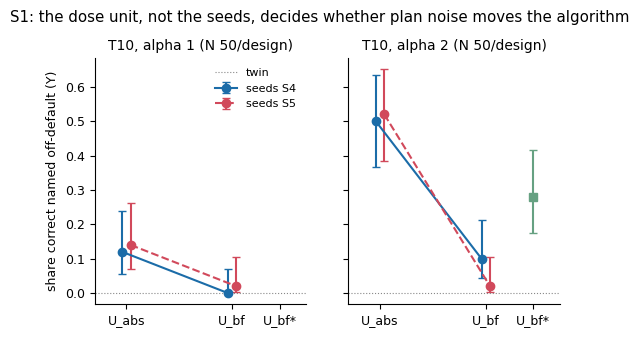

17:08:54|INFO   |figure F1_s1_interaction


In [27]:
def f1(rows) -> None:
    fig, axes = plt.subplots(1, 2 * len(FIG_TASKS), figsize=(6 * len(FIG_TASKS), 3.2), sharey=True)
    for ax, (task, alpha) in zip(axes, [(t, a) for t in FIG_TASKS for a in (1.0, 2.0)]):
        a = "a1" if alpha == 1 else "a2"
        for seeds, (du, db), ls in (("S4", ("D1", "D3"), "-"), ("S5", ("D2", "D4"), "--")):
            ys, lo, hi = [], [], []
            for d in (du, db):
                c = A.cell(rows, task, f"{d}_{a}", A.COMMITTED_KS[(task, alpha)])
                k = sum(r["Y"] for r in c.values())
                n = len(c)
                ys.append(k / n if n else np.nan)
                l, h = wilson(k, n)
                lo.append(max(0.0, ys[-1] - l))
                hi.append(max(0.0, h - ys[-1]))
            x = np.array([0, 1]) + (-0.04 if seeds == "S4" else 0.04)
            ax.errorbar(x, ys, yerr=[lo, hi], fmt="o", ls=ls, color="#1b6ca8" if seeds == "S4" else "#d1495b",
                        capsize=3, label=f"seeds {seeds}")
        c5 = A.cell(rows, task, f"D5_{a}", A.COMMITTED_KS[(task, alpha)])
        if c5:
            k = sum(r["Y"] for r in c5.values())
            n = len(c5)
            l, h = wilson(k, n)
            ax.errorbar([1.45], [k / n], yerr=[[max(0.0, k / n - l)], [max(0.0, h - k / n)]], fmt="s", color=COL["D5"], capsize=3,
                        label="U_bf* x S4 (D5)")
        tw = A.cell(rows, task, "TWIN", K.K20 if task == "T2" else K.K10)
        ax.axhline(sum(r["Y"] for r in tw.values()) / max(len(tw), 1), color="#888", lw=0.8, ls=":", label="twin")
        ax.set_xticks([0, 1, 1.45])
        ax.set_xticklabels(["U_abs", "U_bf", "U_bf*"])
        ax.set_title(f"{task}, alpha {int(alpha)} (N {len(A.cell(rows, task, f'D1_{a}', A.COMMITTED_KS[(task, alpha)]))}/design)")
        ax.set_xlim(-0.3, 1.7)
    axes[0].set_ylabel("share correct named off-default (Y)")
    axes[0].legend(loc="upper right", frameon=False)
    fig.suptitle("S1: the dose unit, not the seeds, decides whether plan noise moves the algorithm", y=1.03)
    save(fig, "F1_s1_interaction")


run_figure(lambda: f1(rows))

**F2: the dose units in activation coordinates** (T10, template W1, blocks 12–23 × the 145 task-spec tokens, in
residual-stream norm units).
- **U_abs is peaky.** Its top quartile of cells holds about 81% of its energy, on bands of a few task tokens.
- **U_bf is flat by construction.** It follows the twin's residual norm ‖h_twin‖.
- **U_bf\*, P_top, P_rest and P_shuf** are the reshaped arms of D5 and S2.

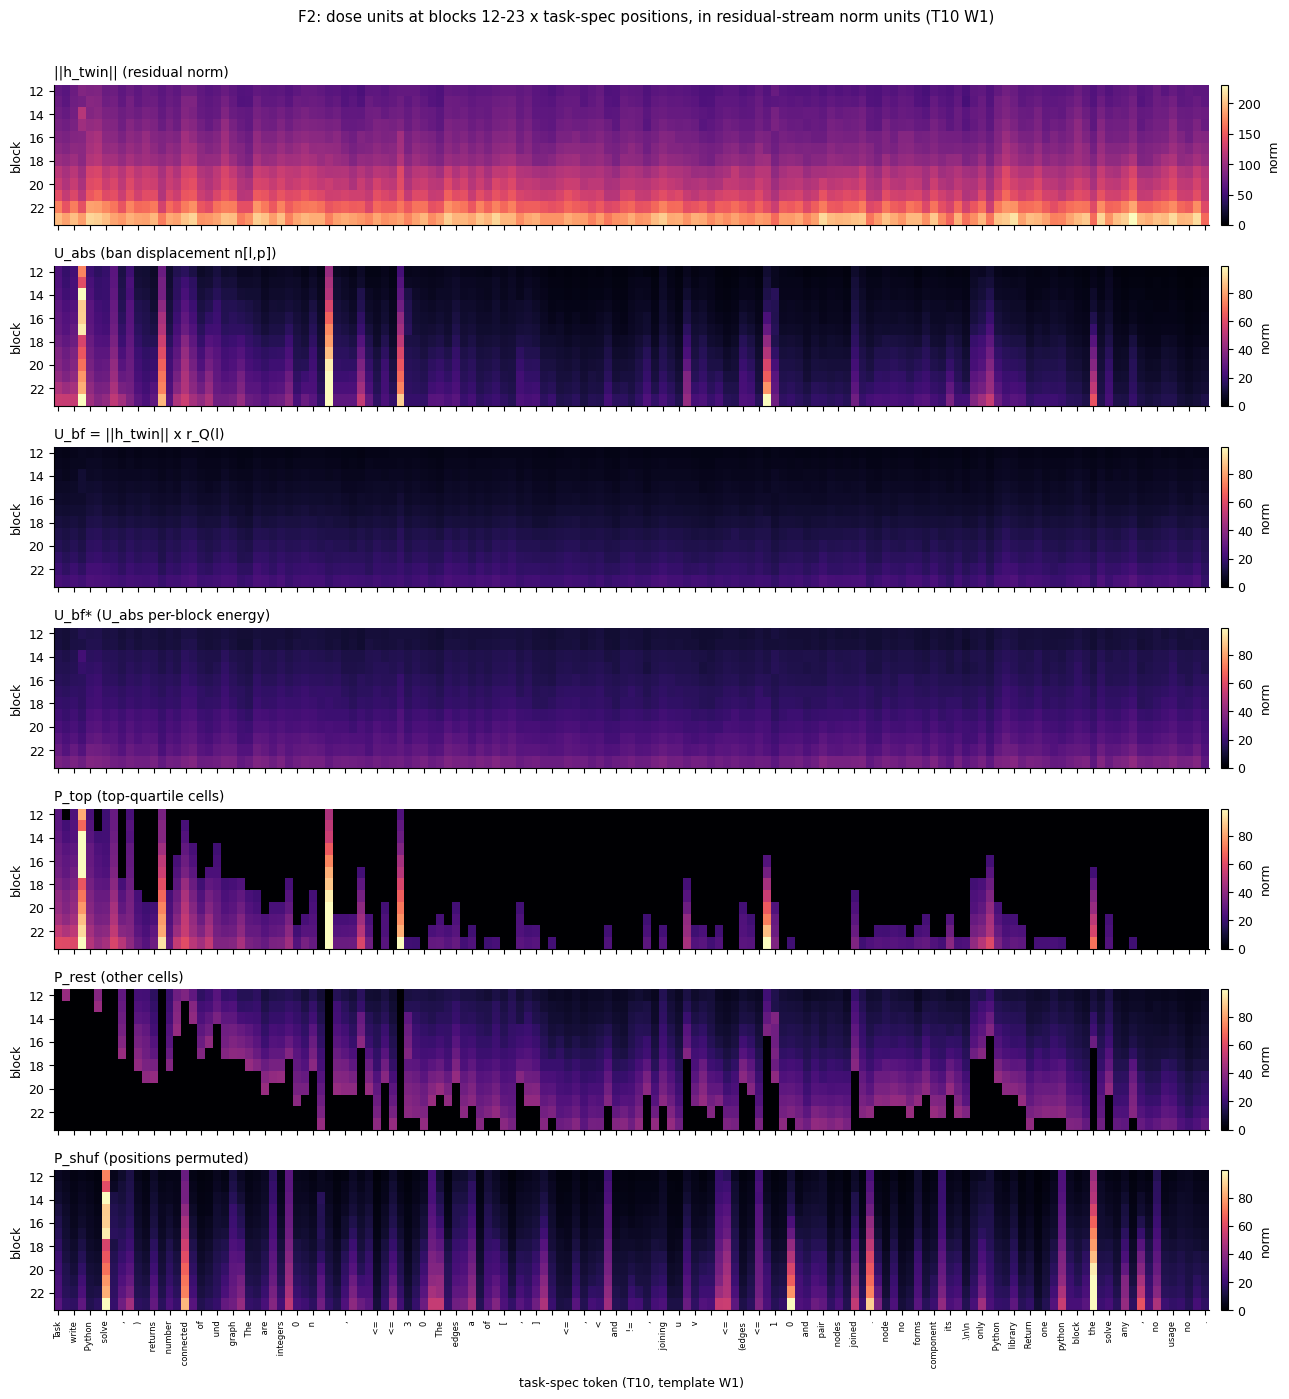

17:08:56|INFO   |figure F2_unit_heatmaps


In [28]:
def f2() -> None:
    # demo: the dose-unit dump (cache/units/T10.npz) comes from the loaded data
    z = {k: (v if k.startswith("tokens") else np.array(v, dtype=np.float32)) for k, v in data["metadata"]["units_T10"].items()}
    toks = [t.replace("\n", "\\n") for t in z["tokens_W1"]]
    mats = [("||h_twin|| (residual norm)", z["h_norm_W1"]), ("U_abs (ban displacement n[l,p])", z["U_abs"]),
            ("U_bf = ||h_twin|| x r_Q(l)", z["U_bf_W1"]), ("U_bf* (U_abs per-block energy)", z["U_bf_star_W1"]),
            ("P_top (top-quartile cells)", z["P_top"]), ("P_rest (other cells)", z["P_rest"]),
            ("P_shuf (positions permuted)", z["P_shuf"])]
    fig, axes = plt.subplots(len(mats), 1, figsize=(13, 2.0 * len(mats)), sharex=True)
    vmax = max(float(np.percentile(m, 99.5)) for _, m in mats[1:])
    for ax, (title, m) in zip(axes, mats):
        im = ax.imshow(m, aspect="auto", cmap="magma", vmin=0, vmax=(None if title.startswith("||h") else vmax),
                       interpolation="nearest")
        ax.set_yticks(range(0, 12, 2))
        ax.set_yticklabels([str(12 + i) for i in range(0, 12, 2)])
        ax.set_ylabel("block")
        ax.set_title(title, loc="left")
        plt.colorbar(im, ax=ax, pad=0.01, fraction=0.02, label="norm")
    step = max(1, len(toks) // 60)
    axes[-1].set_xticks(range(0, len(toks), step))
    axes[-1].set_xticklabels([toks[i][:10] for i in range(0, len(toks), step)], rotation=90, fontsize=6)
    axes[-1].set_xlabel("task-spec token (T10, template W1)")
    fig.suptitle("F2: dose units at blocks 12-23 x task-spec positions, in residual-stream norm units (T10 W1)", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    save(fig, "F2_unit_heatmaps")


run_figure(f2)

**F3: the realised displacement against the clean twin, per block** (α 2, mean over rows, log scale). Three
positions are shown: the spec-position mean, the read position R (the last prompt token) and generated position 1.
The edit acts on blocks 12–23 (grey band), and blocks 0–11 are exactly 0. At block 35, U_abs (D1, D2) and U_bf
(D3, D4) reach similar displacement sizes at the read position and at generated position 1; the spec-mean differs
more. Yet U_abs escapes 5–25× more often.

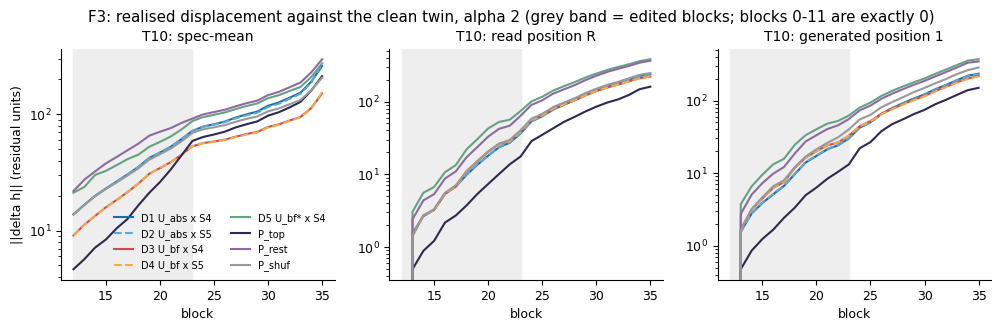

17:08:57|INFO   |figure F3_displacement_blocks


In [29]:
def f3() -> None:
    rec = [x for ex in data["examples"][:MAX_EXAMPLES] for x in ex["realised"]]  # demo: instead of read_jsonl(K.REALISED)
    fig, axes = plt.subplots(len(FIG_TASKS), 3, figsize=(12, 3 * len(FIG_TASKS)), sharex=True, squeeze=False)
    for i, task in enumerate(FIG_TASKS):
        for j, (fld, lab) in enumerate((("spec_mean", "spec-mean"), ("R", "read position R"),
                                        ("gen1", "generated position 1"))):
            ax = axes[i, j]
            by = defaultdict(list)
            for r in rec:
                if r["task"] == task and r.get("alpha") == 2.0 and r.get(fld):
                    by[r["design"]].append(r[fld])
            for d in ("D1", "D2", "D3", "D4", "D5", "PTOP", "PREST", "PSHUF"):
                if by.get(d):
                    m = np.mean(np.array(by[d]), axis=0)
                    ax.plot(range(12, 36), m[12:], color=COL[d], label=NAME[d],
                            ls="--" if d in ("D2", "D4") else "-")
            ax.set_yscale("log")
            ax.axvspan(12, 23, color="#eee", zorder=0)
            ax.set_title(f"{task}: {lab}")
            if j == 0:
                ax.set_ylabel("||delta h|| (residual units)")
            if i == len(FIG_TASKS) - 1:
                ax.set_xlabel("block")
    axes[0, 0].legend(frameon=False, ncol=2, fontsize=7)
    fig.suptitle("F3: realised displacement against the clean twin, alpha 2 (grey band = edited blocks; blocks 0-11 are exactly 0)", y=1.01)
    save(fig, "F3_displacement_blocks")


run_figure(f3)

**F4: does the size of the downstream displacement predict which samples escape?** Each point is one pushed program
(α 1 and 2, jittered vertically): escaped (Y = 1) or not, plotted against its block-35 read-position displacement
norm. The designs overlap in displacement size but not in escape rate.

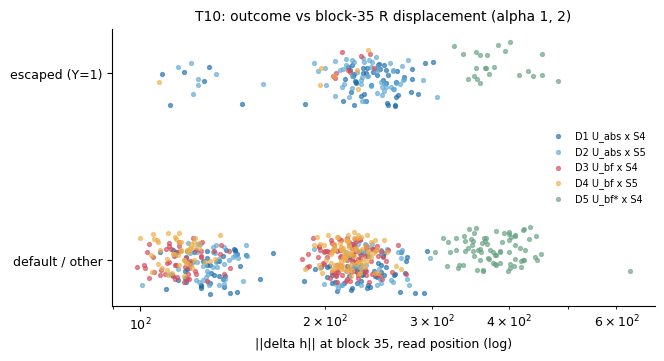

17:08:57|INFO   |figure F4_escape_vs_disp


In [30]:
def f4(rows) -> None:
    fig, axes = plt.subplots(1, len(FIG_TASKS), figsize=(7 * len(FIG_TASKS), 3.6), squeeze=False)
    rng = np.random.default_rng(0)
    for ax, task in zip(axes[0], FIG_TASKS):
        for i, d in enumerate(("D1", "D2", "D3", "D4", "D5")):
            sel = [r for r in rows if r["task"] == task and r["design"] == d and r.get("labelled")
                   and r.get("realised_disp") and r["alpha"] in (1.0, 2.0)]
            if not sel:
                continue
            x = np.array([r["realised_disp"]["R_b35"] for r in sel])
            y = np.array([r["Y"] for r in sel]) + rng.uniform(-0.12, 0.12, len(sel)) + (i - 2) * 0.03
            ax.scatter(x, y, s=8, alpha=0.6, color=COL[d], label=NAME[d])
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["default / other", "escaped (Y=1)"])
        ax.set_xscale("log")
        ax.set_xlabel("||delta h|| at block 35, read position (log)")
        ax.set_title(f"{task}: outcome vs block-35 R displacement (alpha 1, 2)")
    axes[0, 0].legend(frameon=False, fontsize=7, loc="center right")
    save(fig, "F4_escape_vs_disp")


run_figure(lambda: f4(rows))

**F5: the geometry of the downstream displacement in activation space.** This is a PCA of the actual 4,096-d
block-35 read-position displacement vectors (fp16, against the clean twin) of the α-2 pushes on the committed slots.
- colour: the algorithm the program realised;
- marker: the design;
- P_rest is excluded, as in the original.

The demo data ships these vectors for the 50 committed slots only. The artifact's F5 also used the 50 fresh slots.

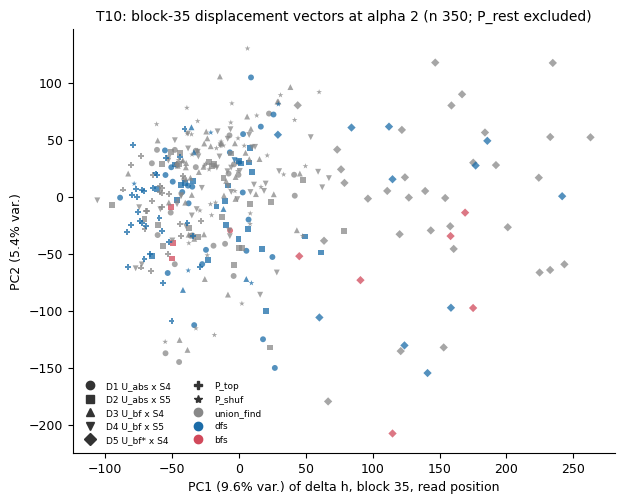

17:08:58|INFO   |figure F5_pca_disp35


In [31]:
def f5(rows) -> None:
    lab = {r["key"]: r for r in rows}
    vecs = defaultdict(dict)
    for ex in data["examples"][:MAX_EXAMPLES]:  # demo: the fp16 R35 vectors of cache/disp/*.npz from the loaded data
        for key, b64 in ex["disp_R35"].items():
            vecs[key.split("|")[0]][key] = np.frombuffer(base64.b64decode(b64), dtype=np.float16).astype(np.float32)
    fig, axes = plt.subplots(1, len(FIG_TASKS), figsize=(7 * len(FIG_TASKS), 5.5), squeeze=False)
    marks = {"D1": "o", "D2": "s", "D3": "^", "D4": "v", "D5": "D", "PTOP": "P", "PREST": "X", "PSHUF": "*"}
    cmap = {"union_find": "#888888", "dfs": "#1b6ca8", "bfs": "#d1495b", "dijkstra": "#888888", "bf_spfa": "#1b6ca8",
            "other": "#66a182", "invalid": "#edae49", "floyd": "#8d6a9f", "disputed": "#000000"}
    for ax, task in zip(axes[0], FIG_TASKS):
        keys = [k for k in vecs.get(task, {}) if k in lab and lab[k].get("labelled") and lab[k]["alpha"] == 2.0
                and lab[k]["design"] != "PREST"]     # P_rest breaks T2 (pass 0) and would own PC1
        if len(keys) < 10:
            continue
        X = np.stack([vecs[task][k] for k in keys])
        Xc = X - X.mean(0)
        U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
        pcs = Xc @ Vt[:2].T
        ev = (S ** 2) / (S ** 2).sum()
        for d, mk in marks.items():
            for lb, c in cmap.items():
                idx = [i for i, k in enumerate(keys) if lab[k]["design"] == d and lab[k]["label"] == lb]
                if idx:
                    ax.scatter(pcs[idx, 0], pcs[idx, 1], marker=mk, s=18, color=c, alpha=0.75, edgecolor="none")
        from matplotlib.lines import Line2D
        h1 = [Line2D([], [], marker=mk, ls="", color="#333", label=NAME[d]) for d, mk in marks.items()
              if any(lab[k]["design"] == d for k in keys)]
        h2 = [Line2D([], [], marker="o", ls="", color=c, label=lb) for lb, c in cmap.items()
              if any(lab[k]["label"] == lb for k in keys)]
        ax.legend(handles=h1 + h2, frameon=False, fontsize=6.5, ncol=2, loc="best")
        ax.set_xlabel(f"PC1 ({100 * ev[0]:.1f}% var.) of delta h, block 35, read position")
        ax.set_ylabel(f"PC2 ({100 * ev[1]:.1f}% var.)")
        ax.set_title(f"{task}: block-35 displacement vectors at alpha 2 (n {len(keys)}; P_rest excluded)")
    save(fig, "F5_pca_disp35")


run_figure(lambda: f5(rows))

**E1: dose response of the ban-free unit next to U_abs.**
- Left: share Y (solid) and pass rate (dotted) against α.
- Right: share Y against the mean block-35 spec-mean displacement.

U_bf needs α ≈ 4 to approach what U_abs does at α 2, and it starts to break programs at α 6.

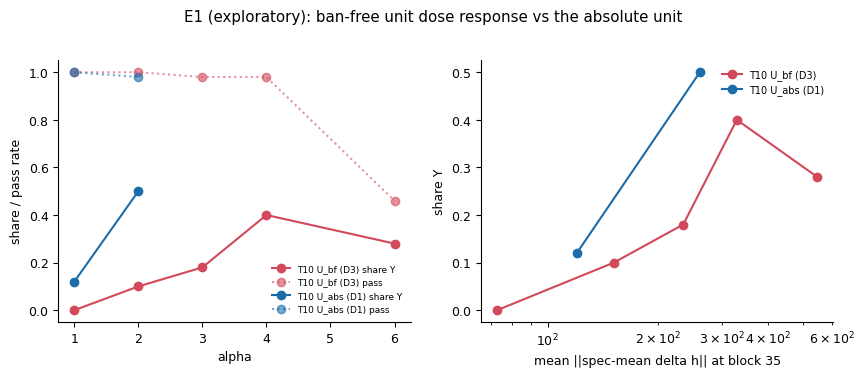

17:08:58|INFO   |figure E1_dose_response


In [32]:
def e1() -> None:
    p = RESULTS / "e1_sweep.json"
    if not p.exists():
        return
    r = read_json(p)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for task, mk in [(t, m) for t, m in (("T10", "o"), ("T2", "s")) if t in FIG_TASKS]:
        d = r.get(task, {})
        for unit, arms, c in (("U_bf (D3)", ["D3_a1", "D3_a2", "D3_a3", "D3_a4", "D3_a6"], "#d1495b"),
                              ("U_abs (D1)", ["D1_a1", "D1_a2"], "#1b6ca8")):
            xs = [float(a.split("_a")[1]) for a in arms if a in d]
            ys = [d[a]["Y"]["share"] for a in arms if a in d]
            ps = [d[a]["pass_rate"] for a in arms if a in d]
            dx = [d[a]["realised_mean"]["S_b35"] for a in arms if a in d and d[a].get("realised_mean")]
            axes[0].plot(xs, ys, marker=mk, color=c, label=f"{task} {unit} share Y")
            axes[0].plot(xs, ps, marker=mk, color=c, ls=":", alpha=0.6, label=f"{task} {unit} pass")
            if len(dx) == len(ys):
                axes[1].plot(dx, ys, marker=mk, color=c, label=f"{task} {unit}")
    axes[0].set_xlabel("alpha")
    axes[0].set_ylabel("share / pass rate")
    axes[0].legend(frameon=False, fontsize=6.5)
    axes[1].set_xlabel("mean ||spec-mean delta h|| at block 35")
    axes[1].set_ylabel("share Y")
    axes[1].set_xscale("log")
    axes[1].legend(frameon=False, fontsize=7)
    fig.suptitle("E1 (exploratory): ban-free unit dose response vs the absolute unit", y=1.03)
    save(fig, "E1_dose_response")


run_figure(e1)

**E3: replication on fresh slots.** Share Y at α 2 per design and profile arm. Left: the committed slots k 0–9
(S1/S2). Right: the fresh slots k 10–19. The T03 panel of the original is dropped (no T03 rows here).

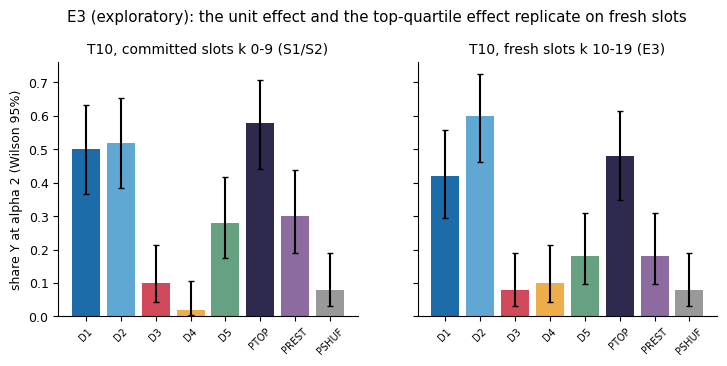

17:08:59|INFO   |figure E3_replicate


In [33]:
def e3() -> None:
    p = RESULTS / "e3_replicate.json"
    if not p.exists():
        return
    r = read_json(p)
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3), sharey=True)
    for ax, (lab, title) in zip(axes, (("T10_k0_9", "T10, committed slots k 0-9 (S1/S2)"),
                                       ("T10_fresh_k10_19", "T10, fresh slots k 10-19 (E3)"))):  # demo: no T03 panel
        if lab == "T10_k0_9":
            s1 = read_json(RESULTS / "s1_2x2.json")["cells"]
            s2 = read_json(RESULTS / "s2_profile.json")["T10"]["cells"]
            cells = {d: s1[f"T10|{d}_a2"] for d in ("D1", "D2", "D3", "D4", "D5")} | {
                {"PTOP": "PTOP", "PREST": "PREST", "PSHUF": "PSHUF"}[k]: v for k, v in s2.items() if k != "D1"}
        elif lab == "T03_k0_9":
            cells = r[lab]["cells"]
        else:
            cells = r[lab]["profiles"]["cells"] | {d: v for d, v in r[lab].get("cells", {}).items()}
            s1c = {}
            n_sl = r[lab]["2x2|Y"]["n_slots"]
            for d in ("D2", "D3", "D4"):
                t = r[lab]["2x2|Y"]["shares"][d]
                s1c[d] = {"Y": {"share": t, "wilson95": list(wilson(int(round(t * n_sl)), n_sl))}}
            cells = {**s1c, **cells}
        order = [d for d in ("D1", "D2", "D3", "D4", "D5", "PTOP", "PREST", "PSHUF") if d in cells]
        ys = [cells[d]["Y"]["share"] for d in order]
        lo = [max(0.0, cells[d]["Y"]["share"] - cells[d]["Y"]["wilson95"][0]) for d in order]
        hi = [max(0.0, cells[d]["Y"]["wilson95"][1] - cells[d]["Y"]["share"]) for d in order]
        ax.bar(range(len(order)), ys, yerr=[lo, hi], color=[COL[d] for d in order], capsize=2)
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, rotation=45, fontsize=7)
        ax.set_title(title)
    axes[0].set_ylabel("share Y at alpha 2 (Wilson 95%)")
    fig.suptitle("E3 (exploratory): the unit effect and the top-quartile effect replicate on fresh slots",
                 y=1.04)
    save(fig, "E3_replicate")


run_figure(e3)

## 10. Results: recomputed here vs reported by the artifact

The table reads the `results/*.json` files the cells above wrote:
- `anchors.json`, `s1_2x2.json`, `s2_profile.json`, `e1_sweep.json` and `e3_replicate.json`;
- next to them, the numbers the artifact reported for T10 (stored in the demo data).

**✓** means identical, **≈** means within 2% (the mediation logits could depend on the scikit-learn version), and
**✗** means different. With the default configuration every row reads ✓. With a reduced `MAX_EXAMPLES`, `N_BOOT` or
`N_FLIP` some rows read n/a or differ, as expected.

Below the table, one panel shows every program of every slot as a cell. It is the paired CRN design at a glance:
each column is one slot (template, k), shared by every arm.

In [34]:
rep = data["metadata"]["reported"]
mine = {n: read_json(RESULTS / f"{n}.json") for n in ("anchors", "s1_2x2", "s2_profile", "e1_sweep", "e3_replicate")
        if (RESULTS / f"{n}.json").exists()}


def g(d, *path):
    for p in path:
        if not isinstance(d, dict) or p not in d:
            return None
        d = d[p]
    return d


def fmt(v):
    if v is None:
        return "n/a"
    if isinstance(v, float):
        return f"{v:.3g}" if v != 0 and abs(v) < 1e-3 else f"{v:.3f}"
    if isinstance(v, dict):
        return " / ".join(fmt(x) for x in v.values())
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(fmt(x) for x in v) + "]"
    return str(v)


def same(a, b):
    if a is None or b is None:
        return "n/a"
    fa, fb = (list(a.values()) if isinstance(a, dict) else a), (list(b.values()) if isinstance(b, dict) else b)
    fa, fb = (fa if isinstance(fa, list) else [fa]), (fb if isinstance(fb, list) else [fb])
    if len(fa) != len(fb):
        return "✗"
    if all(x == y if not isinstance(x, float) else abs(x - y) <= 1e-9 * max(1.0, abs(y)) for x, y in zip(fa, fb)):
        return "✓"
    if all(isinstance(x, (int, float)) and abs(x - y) <= 0.02 * max(abs(y), 1e-9) for x, y in zip(fa, fb)):
        return "≈"
    return "✗"


S1, D5, S2, E3 = ("s1_2x2", "tables", "T10|a2|Y"), ("s1_2x2", "D5_split", "T10|Y"), ("s2_profile", "T10"), "e3_replicate"
P, E = "profile_at_matched_energy (D1 - D5)", "energy_at_banfree_shape (D5 - D3)"
TABLE = [  # (what, path into this notebook's results, path into the reported numbers)
    ("A1  D1 attempts off-default (of 50)", ("anchors", "A1", "attempted_off_default"), ("anchors", "A1", "attempted_off_default")),
    ("A1  Fisher p vs exp29 25/50", ("anchors", "A1", "fisher_p"), ("anchors", "A1", "fisher_p")),
    ("A2  D4 correct off-default (of 50)", ("anchors", "A2", "correct_off_default"), ("anchors", "A2", "correct_off_default")),
    ("A1  D1 per-slot agreement with exp29", ("anchors", "D1_T10_per_slot_agreement_vs_exp29", "agreement"), ("anchors", "D1_T10_per_slot_agreement_vs_exp29", "agreement")),
    ("S1  T10 a2 shares D1 / D2 / D3 / D4", S1 + ("shares",), ("s1_tables", "T10|a2|Y", "shares")),
    ("S1  unit RD", S1 + ("RD_unit",), ("s1_tables", "T10|a2|Y", "RD_unit")),
    ("S1  unit RD 95% CI", S1 + ("RD_unit_ci95",), ("s1_tables", "T10|a2|Y", "RD_unit_ci95")),
    ("S1  seed RD", S1 + ("RD_seed",), ("s1_tables", "T10|a2|Y", "RD_seed")),
    ("S1  seed RD 95% CI", S1 + ("RD_seed_ci95",), ("s1_tables", "T10|a2|Y", "RD_seed_ci95")),
    ("S1  interaction", S1 + ("RD_int",), ("s1_tables", "T10|a2|Y", "RD_int")),
    ("S1  interaction 95% CI", S1 + ("RD_int_ci95",), ("s1_tables", "T10|a2|Y", "RD_int_ci95")),
    ("S1  Holm p unit / int / seed", S1 + ("holm",), ("s1_tables", "T10|a2|Y", "holm")),
    ("S1  clogit beta unit / seed / unit:seed", S1 + ("clogit", "coef"), ("s1_tables", "T10|a2|Y", "clogit", "coef")),
    ("S1  decision (committed rule)", ("s1_2x2", "decision_T10_a2"), ("s1_decision_T10_a2",)),
    ("S1  T10 a1 unit RD", ("s1_2x2", "tables", "T10|a1|Y", "RD_unit"), ("s1_tables", "T10|a1|Y", "RD_unit")),
    ("S1  T10 a2 attempted (A) shares", ("s1_2x2", "tables", "T10|a2|A", "shares"), ("s1_tables", "T10|a2|A", "shares")),
    ("D5  shares D1 / D5 / D3", D5 + ("shares",), ("D5_split", "T10|Y", "shares")),
    ("D5  profile at matched energy RD, CI", D5 + (P, "ci95"), ("D5_split", "T10|Y", P, "ci95")),
    ("D5  profile McNemar n10 / n01 / p", D5 + (P, "mcnemar"), ("D5_split", "T10|Y", P, "mcnemar")),
    ("D5  energy at ban-free shape RD, CI", D5 + (E, "ci95"), ("D5_split", "T10|Y", E, "ci95")),
    ("D5  energy McNemar n10 / n01 / p", D5 + (E, "mcnemar"), ("D5_split", "T10|Y", E, "mcnemar")),
    ("Med D3 coef with block-35 norms", ("s1_2x2", "mediation", "T10", "Y", "design_coef_with_mediators", "D3"), ("mediation", "Y", "design_coef_with_mediators", "D3")),
    ("Med D4 coef with block-35 norms", ("s1_2x2", "mediation", "T10", "Y", "design_coef_with_mediators", "D4"), ("mediation", "Y", "design_coef_with_mediators", "D4")),
    ("S2  energy share of U_abs top quartile", S2 + ("energy_share_Q4",), ("s2", "energy_share_Q4")),
    ("S2  P_top vs P_rest McNemar", S2 + ("tests", "PTOP_vs_PREST|Y"), ("s2", "tests", "PTOP_vs_PREST|Y")),
    ("S2  D1 vs P_shuf McNemar", S2 + ("tests", "D1_vs_PSHUF|Y"), ("s2", "tests", "D1_vs_PSHUF|Y")),
    ("S2  Holm p (Y tests)", S2 + ("holm_Y",), ("s2", "holm_Y")),
    ("S2  reading", ("s2_profile", "reading_T10"), ("s2_reading_T10",)),
    ("E1  D3 share Y at alpha 3", ("e1_sweep", "T10", "D3_a3", "Y", "share"), ("e1_sweep", "D3_a3", "Y", "share")),
    ("E1  D3 share Y at alpha 4", ("e1_sweep", "T10", "D3_a4", "Y", "share"), ("e1_sweep", "D3_a4", "Y", "share")),
    ("E1  D3 pass rate at alpha 6", ("e1_sweep", "T10", "D3_a6", "pass_rate"), ("e1_sweep", "D3_a6", "pass_rate")),
    ("E3  fresh k10-19 shares D1 / D2 / D3 / D4", (E3, "T10_fresh_k10_19", "2x2|Y", "shares"), ("e3", "T10_fresh_k10_19", "2x2|Y", "shares")),
    ("E3  fresh unit RD, CI", (E3, "T10_fresh_k10_19", "2x2|Y", "RD_unit_ci95"), ("e3", "T10_fresh_k10_19", "2x2|Y", "RD_unit_ci95")),
    ("E3  fresh decision rule", (E3, "T10_fresh_k10_19", "2x2|Y", "decision_rule_applied"), ("e3", "T10_fresh_k10_19", "2x2|Y", "decision_rule_applied")),
    ("E3  pooled k0-19 unit RD", (E3, "T10_pooled_k0_19", "2x2|Y", "RD_unit"), ("e3", "T10_pooled_k0_19", "2x2|Y", "RD_unit")),
    ("E3  fresh P_top vs P_rest McNemar", (E3, "T10_fresh_k10_19", "profiles", "PTOP_vs_PREST"), ("e3", "T10_fresh_k10_19", "profiles", "PTOP_vs_PREST")),
]
w = max(len(x[0]) for x in TABLE)
print(f"{'quantity':<{w}}  {'recomputed here':<38} {'reported':<38} match")
print("-" * (w + 86))
marks = Counter()
for what, pm, pr in TABLE:
    a, b = g(mine.get(pm[0], {}), *pm[1:]), g(rep, *pr)
    if isinstance(a, dict) and isinstance(b, dict) and set(b) <= set(a):
        a = {k: a[k] for k in b}  # same keys, same order as the reported entry
    m = same(a, b)
    marks[m] += 1
    print(f"{what:<{w}}  {fmt(a):<38} {fmt(b):<38} {m}")
print("-" * (w + 86))
print(dict(marks))

quantity                                   recomputed here                        reported                               match
-------------------------------------------------------------------------------------------------------------------------------
A1  D1 attempts off-default (of 50)        26                                     26                                     ✓
A1  Fisher p vs exp29 25/50                1.000                                  1.000                                  ✓
A2  D4 correct off-default (of 50)         1                                      1                                      ✓
A1  D1 per-slot agreement with exp29       0.980                                  0.980                                  ✓
S1  T10 a2 shares D1 / D2 / D3 / D4        0.500 / 0.520 / 0.100 / 0.020          0.500 / 0.520 / 0.100 / 0.020          ✓
S1  unit RD                                0.450                                  0.450                                  ✓
S1  uni

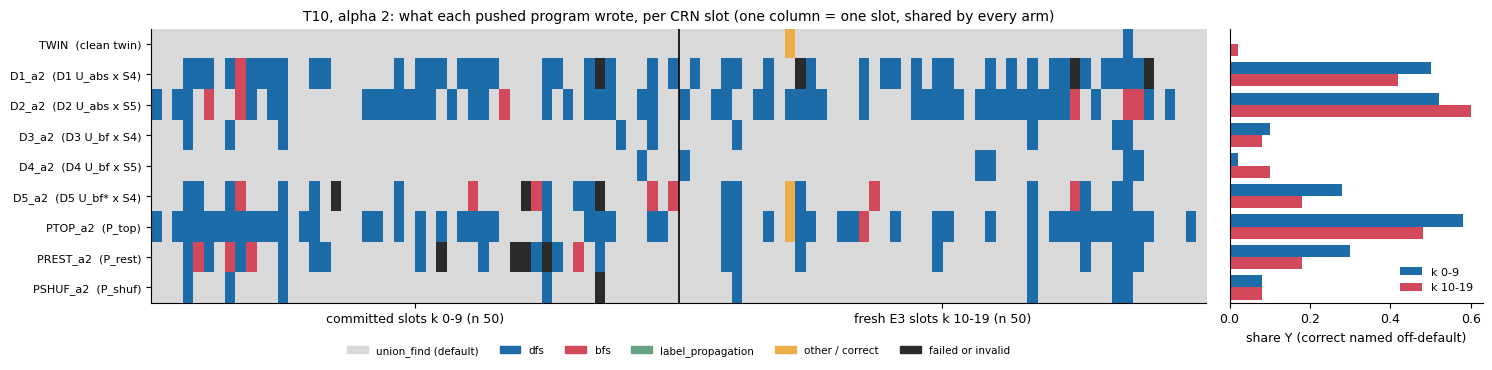

In [35]:
# Notebook addition: every program of every slot, coloured by what it wrote (columns = CRN slots, rows = arms)
ARMS = ["TWIN", "D1_a2", "D2_a2", "D3_a2", "D4_a2", "D5_a2", "PTOP_a2", "PREST_a2", "PSHUF_a2"]
CATS = ["union_find (default)", "dfs", "bfs", "label_propagation", "other / correct", "failed or invalid", "not run"]
CCOL = ["#d9d9d9", "#1b6ca8", "#d1495b", "#66a182", "#edae49", "#2b2b2b", "#ffffff"]
by_key = {r["key"]: r for r in rows}
slots = [(ex["template"], ex["k"]) for ex in data["examples"][:MAX_EXAMPLES]]
slots.sort(key=lambda s: (s[1] >= 10, s[0], s[1]))          # committed k 0-9 first, then the fresh k 10-19
G = np.full((len(ARMS), len(slots)), CATS.index("not run"))
for j, (w_, k_) in enumerate(slots):
    for i, arm in enumerate(ARMS):
        x = by_key.get(f"T10|{w_}|{arm}|{k_}")
        if x is None or not x.get("labelled"):
            continue
        if not x["passed"]:
            G[i, j] = CATS.index("failed or invalid")
        elif x["label"] in ("union_find", "dfs", "bfs", "label_propagation"):
            G[i, j] = [c.split(" ")[0] for c in CATS].index(x["label"])
        else:
            G[i, j] = CATS.index("other / correct")

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
fig, (ax, axb) = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [5, 1.2]})
ax.imshow(G, aspect="auto", cmap=ListedColormap(CCOL), vmin=0, vmax=len(CATS) - 1, interpolation="nearest")
ax.set_yticks(range(len(ARMS)))
ax.set_yticklabels([f"{a}  ({NAME.get(a.split('_a')[0], 'clean twin')})" for a in ARMS], fontsize=8)
n_comm = sum(1 for s in slots if s[1] < 10)
if 0 < n_comm < len(slots):
    ax.axvline(n_comm - 0.5, color="k", lw=1.2)
ax.set_xticks([n_comm / 2 - 0.5] + ([n_comm + (len(slots) - n_comm) / 2 - 0.5] if n_comm < len(slots) else []))
ax.set_xticklabels([f"committed slots k 0-9 (n {n_comm})"] + ([f"fresh E3 slots k 10-19 (n {len(slots) - n_comm})"] if n_comm < len(slots) else []))
ax.set_title("T10, alpha 2: what each pushed program wrote, per CRN slot (one column = one slot, shared by every arm)")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(CCOL[:-1], CATS[:-1])], ncol=6, fontsize=7.5,
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
for part, (lo, hi), col in (("k 0-9", (0, 10), "#1b6ca8"), ("k 10-19", (10, 20), "#d1495b")):
    ys = []
    for arm in ARMS:
        sel = [by_key[f"T10|{w_}|{arm}|{k_}"] for (w_, k_) in slots if lo <= k_ < hi and f"T10|{w_}|{arm}|{k_}" in by_key]
        ys.append(np.mean([x["Y"] for x in sel]) if sel else np.nan)
    axb.barh(np.arange(len(ARMS)) + (-0.2 if lo == 0 else 0.2), ys, height=0.4, color=col, label=part)
axb.set_ylim(len(ARMS) - 0.5, -0.5)
axb.set_yticks([])
axb.set_xlabel("share Y (correct named off-default)")
axb.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Reading the results.**

- **The answer is the unit, not the seeds.** On T10 at α 2 the U_abs designs (D1, D2) escape union-find on about
  half of the slots. The U_bf designs (D3, D4) almost never do, and swapping the S4 and S5 directions changes nothing.
  So iteration 5's null came from its ban-free dose unit, not from its seeds or its decoding path: both anchors
  reproduce on the shared-prefix path.
- **Both halves of the unit matter.** U_bf\* (D5) lands between the two units. U_abs's peaky profile and its
  per-block energy each contribute.
- **Pushes act where bans write.** The top quartile of U_abs's cells (81% of its energy) carries the effect; the rest
  carries much less. Moving the same dose to other token positions (P_shuf) kills it.
- **Size of the downstream displacement is not the mechanism.** U_abs and U_bf reach similar block-35 displacement
  norms (F3, F4), and adding those norms to the per-sample logit leaves the design coefficients unchanged.
- **Exploratory.** U_bf needs about twice the α (≈ 4) to approach U_abs at α 2, at a growing pass cost (E1). The unit
  effect replicates on 50 fresh slots (E3).

**Not re-run in this notebook.** These parts need the GPU, the earlier artifacts or the other tasks. They are reported
in the artifact's README and `results/`.
- **S3 prices** at D\* = D1 against iteration 5's text-level samplers, on T03, T10, T2, T05 and T1. PN\* beat
  base-model intents on 2 of 5 tasks.
- **The novelty audit.** All 5 correct "other" programs were catalogue variants; 0 were novel.
- **E2 geometry.** Escape is close to a coin flip per (direction, token stream): φ 0.16–0.20, and the CV AUC from the
  block-35 displacement is 0.40–0.53.
- **The audits.** CPU gates G1–G5, GPU unit tests U1–U6, the sha256 commit chain, and the stdlib re-derivation with
  placebos (0 mismatches).
- **The T2 and T03 replications.** T2 unit RD +0.115 (with its massive-activation caveat); T03 unit RD +0.27.